# D57 vLLM Basics Code

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

last modified date : 2026.11

# vLLM 기초 구현 실습

## 오늘 확인할 문제

**검증한 모델 파일을 vLLM 서버로 실행하고 여러 요청에 답하게 하려면 무엇을 설정해야 합니까?**

D56에서 저장한 모델 파일로 vLLM 서버를 실행합니다. 클라이언트에서 서버에 질문을 보내 답을 확인하고, 여러 요청이 동시에 들어올 때 처리 시간과 대기 상태를 측정합니다. 마지막에는 D53 챗봇의 응답 형식을 유지하면서 답을 생성하는 함수를 vLLM 서버 호출로 바꿉니다.

먼저 답과 이유를 두 문장으로 적습니다. 실습을 마치면 처음 판단을 자신의 결과로 고칩니다.

**학습목표**

- [목표 1] 직접 만든 7B 파일을 vLLM으로 기동하고 요청·응답을 확인할 수 있다.
- [목표 2] 메모리·입력 길이·동시 처리 설정을 바꾸어 응답 목표를 만족하는 운영 조건을 고를 수 있다.
- [목표 3] 챗봇의 응답 형식을 유지하며 생성 함수를 vLLM 호출로 교체하고 검사할 수 있다.

오늘은 RunPod 묶음의 둘째 날입니다. 어제 팀 볼륨에 받아 둔 Qwen2.5-32B-Instruct-AWQ를 vLLM으로 서빙하고 양자화 노트 벤치마크 하네스의 질문 30개로 세 방식을 비교합니다. transformers로 요청을 하나씩 처리하는 방식(7B 16비트), vLLM의 오프라인 `LLM`, vLLM의 OpenAI 호환 서버입니다.

처음 해 보는 일은 **팀원마다 vLLM 설정 하나를 맡아 서버를 직접 기동하고 측정한 뒤 팀 결과표 한 장으로 모으는 것**입니다. 마지막에는 서빙 프로젝트(52일차) 서버의 `generate_reply`를 vLLM 주소 호출로 바꾸고 52일차의 채점 항목을 다시 실행합니다.

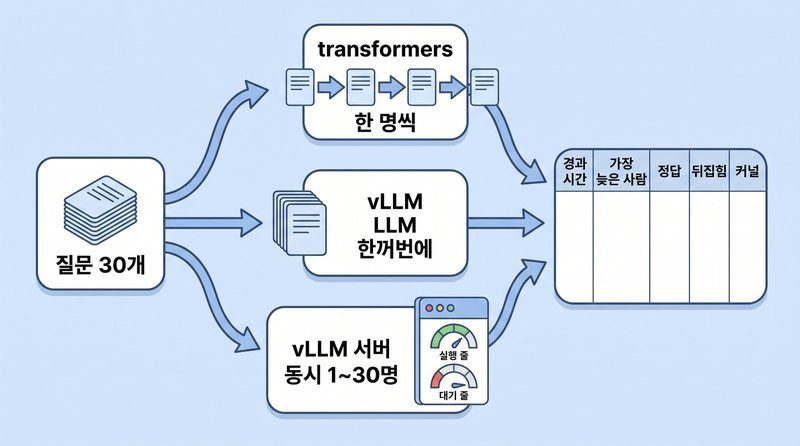

*같은 질문 30개를 세 가지 방식으로 보내고 경과 시간과 최대 지연 시간을 한 표에 놓습니다.*

## 이론과 실습을 잇는 순서

| 학습 구간 | 계획 시간 | 연결 위치 |
|---|---:|---|
| 요청 처리 방식과 기존 성능 확인 | 65분 | 이론 1\~2장, Step 0\~2 |
| KV 캐시 관리와 vLLM 직접 호출 | 75분 | 이론 3장, Step 3\~4 |
| 모델 서버 실행과 동시 요청 실험 | 135분 | 이론 4\~5장, Step 5\~6 |
| 챗봇 연결·응답 검사·결과 저장 | 85분 | 이론 6장, Step 7·9 |

이론 설명과 필수 실습을 합쳐 360분으로 계획했습니다. 휴식 40분, 점심 60분, 설치·오류 대응 여유 20분을 포함하면 하루 480분입니다. 표의 연결 위치를 따라 이론을 읽고 해당 실습을 이어서 진행합니다. 선택 실습과 접힌 심화 자료를 모두 추가하지 않습니다. 이 시간은 수업 계획이며 실제 진행 시간을 측정한 값은 아닙니다.

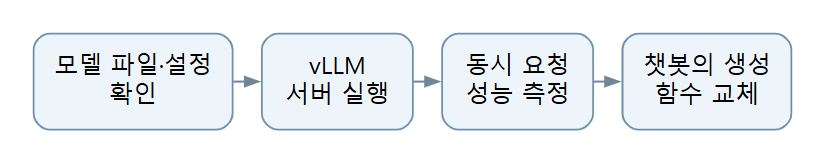

**실습 순서.** 모델 파일·설정 확인 → vLLM 서버 실행 → 동시 요청 성능 측정 → 챗봇의 생성 함수 교체 순서로 진행합니다.

### 먼저 읽을 용어

| 용어 | 뜻과 실제로 하는 일 |
|---|---|
| 서빙 엔진 |  모델을 실행하고 들어온 생성 요청을 처리하는 프로그램 |
| 연속 배칭 |  진행 중인 생성 작업에 새 요청을 합류시키는 처리 방식 |
| KV 블록 |  이전 토큰의 계산 결과인 KV 캐시를 나누어 보관하는 메모리 단위 |
| SLO |  첫 응답 시간 등 서비스가 지키려는 성능 목표 |

## 실행 환경

이 노트는 **어제와 같은 팀 RunPod Pod**(48GB급 GPU 1장, 팀 네트워크 볼륨 `/workspace`)를 기준으로 씁니다. GPU 이름은 A40 또는 RTX A6000을 우선 사용하고, 같은 데이터센터에 재고가 없으면 L40S를 확인이고 요금은 RunPod 요금표에서 확인합니다.

<div style="font-size: 18px; line-height: 1.6;">

| 항목 | 내용 |
|---|---|
| 런타임 | 팀 RunPod Pod, 48GB급 GPU 1장(80GB급이면 여유). 56일차와 같은 네트워크 볼륨을 `/workspace`에 마운트 |
| 버전 | vLLM 0.30.0과 그 버전이 고르는 torch 2.13.0, transformers 5.17 이상 |
| 모델 파일 | `HF_HOME=/workspace/hf`에 56일차에 받아 둔 Qwen2.5-32B-Instruct-AWQ(19.3GB), Qwen2.5-7B-Instruct. 오늘은 새로 받지 않습니다 |
| 로드하는 모델 | 7B 16비트(transformers 한 번, vLLM 한 번), 32B 4비트(vLLM 여러 번). 한 번에 하나씩 |
| 기동하는 서비스 | vLLM 서버 1개(포트 8570부터), 서빙 프로젝트 서버 1개(포트 8000부터). 모두 `127.0.0.1` |
| 결과 파일 | `/workspace/results/d57/d57_results.json`, `d57_team_table.csv`. 56일차 결과는 `/workspace/results/d56` |
| 필요한 키 | 없음. vLLM 서버의 키와 서빙 프로젝트의 키는 실습용 값을 씁니다 |

</div>

<div style="font-size: 18px; line-height: 1.6;">

| 오래 걸리는 셀 | 하는 일 | 대략 (추정) |
|---|---|---|
| Step 0 설치 | vLLM, torch 2.13.0. Pod를 재개할 때마다 다시 실행 | 5\~10분 |
| Step 2 기준선 | 7B 로드, 30문항 하나씩 | 3\~6분 |
| Step 3 오프라인 엔진 | 32B 4비트 로드, 메모리 측정, 컴파일 | 3\~8분 |
| Step 5 팀원 측정 | 팀원마다 서버를 한 번씩 기동, 측정, 종료 | 팀원마다 5\~10분 |
| Step 6 곡선 | 팀이 고른 설정으로 서버를 다시 기동하고 동시 요청 6단계 | 10\~20분 |
| 트랙 | 서버를 한두 번 더 기동함 | 트랙마다 10\~30분 |

</div>

### 팀 운영

**GPU 한 장에는 vLLM 서버를 하나만 기동합니다.** 그래서 팀원 네 명이 vLLM 설정 하나씩을 맡아 차례로 자기 서버를 기동하고 측정하고 종료합니다. 노트북 하나를 화면에 띄워 함께 따라가고 역할표의 셀은 그 담당이 직접 실행합니다.

<div style="font-size: 18px; line-height: 1.6;">

| 역할 | 맡는 것 | 직접 실행하는 셀 | 이름 |
|---|---|---|---|
| A | `gpu_memory_utilization` | Step 3 오프라인 `LLM`, Step 5 기준 서버 기동과 비율을 낮춘 서버 | |
| B | `max_model_len` | Step 5 B 셀, Step 7 생성 백엔드 교체(C와 짝) | |
| C | `max_num_seqs` | Step 5 C 셀, Step 7 52일차 채점(B와 짝) | |
| D | 4비트 32B와 16비트 7B | Step 5 D 셀(7B 16비트 서버) | |
| 모두 | Step 0\~2, Step 4, Step 6 팀 결과표와 설정 결정, 공유와 정리 | | |

</div>

**Pod 운영 규칙**

1. 서버를 기동하기 전에 `nvidia-smi`로 다른 팀원의 서버나 커널이 GPU를 쓰고 있지 않은지 봅니다
2. 자기가 기동한 서버는 자기가 종료합니다. Step 5의 팀원 셀은 측정이 끝나면 서버를 스스로 종료합니다
3. 결과는 모두 `/workspace/results/d57`에 남깁니다. 컨테이너 디스크는 Pod를 멈추면 지워집니다
4. 두 팀은 같은 표 형식으로 결과를 남기고 공유와 정리에서 두 팀 표를 나란히 놓습니다

## Step 0. Pod 재개와 볼륨의 모델 확인

RunPod 콘솔에서 어제의 팀 Pod를 시작합니다. 어제 Pod를 종료(terminate)했다면 같은 네트워크 볼륨을 붙여 새 Pod를 만듭니다. 네트워크 볼륨은 Pod를 만들 때만 붙일 수 있고 볼륨을 만든 데이터센터의 GPU만 고를 수 있습니다.

Pod의 Jupyter에서 이 노트북을 열고 **설치 셀을 torch를 불러오기 전에 맨 먼저 실행합니다.** 컨테이너 디스크의 패키지는 Pod를 멈추면 지워지므로 Pod를 재개할 때마다 다시 설치합니다.

In [1]:
import subprocess
import sys

pip = [sys.executable, "-m", "pip"]

subprocess.run(
    pip + ["install", "--user", "--ignore-installed", "--no-deps", "PyJWT>=2.10.1,<3"],
    check=True,
)
subprocess.run(
    pip + [
        "install",
        "vllm==0.30.0",
        "transformers>=5.17,<6",
        "accelerate",
        "httpx",
        "pandas",
        "matplotlib",
    ],
    check=True,
)

print("설치 완료. Kernel → Restart Kernel 후 셀 2부터 실행하세요.")

  Using cached pyjwt-2.15.1-py3-none-any.whl.metadata (3.5 kB)
Using cached pyjwt-2.15.1-py3-none-any.whl (33 kB)
설치 완료. Kernel → Restart Kernel 후 셀 2부터 실행하세요.


In [2]:
import gc, json, math, os, re, shutil, socket, subprocess, sys, threading, time
from collections import Counter
from pathlib import Path
from importlib.metadata import version

print({d: version(d) for d in ["vllm", "torch", "transformers", "fastapi", "PyJWT"]})

{'vllm': '0.30.0', 'torch': '2.13.0+cu130', 'transformers': '5.22.2', 'fastapi': '0.136.3', 'PyJWT': '2.15.1'}


In [3]:
import torch

if not torch.cuda.is_available():
    subprocess.run(["nvidia-smi"], check=False)
    raise RuntimeError("PyTorch가 GPU를 인식하지 못했습니다. 위 nvidia-smi 출력을 확인하세요.")

CAP = torch.cuda.get_device_capability(0)
GPU_NAME = torch.cuda.get_device_name(0)
TOTAL_GIB = torch.cuda.mem_get_info(0)[1] / 1024**3
DTYPE16 = torch.float16
VLLM_DTYPE = os.environ.get("D57_VLLM_DTYPE", "half")

print(f"{GPU_NAME} / compute capability {CAP[0]}.{CAP[1]} / 전체 {TOTAL_GIB:.1f} GiB")
print(f"torch {torch.__version__} / CUDA {torch.version.cuda} / dtype {DTYPE16}")

NVIDIA A40 / compute capability 8.6 / 전체 44.4 GiB
torch 2.13.0+cu130 / CUDA 13.0 / dtype torch.float16


In [4]:
os.environ.setdefault("HF_HOME", "/workspace/hf")
os.environ.setdefault("VLLM_NO_USAGE_STATS", "1")

WORK = Path("/workspace/d57")
RESULTS = Path("/workspace/results/d57")
D56_RESULTS = Path(os.environ.get("D56_RESULTS", "/workspace/results/d56"))

MODEL_ID = os.environ.get("MODEL_ID", "Qwen/Qwen2.5-32B-Instruct-AWQ")
MODEL_16 = os.environ.get("D57_MODEL_16", "Qwen/Qwen2.5-7B-Instruct")
TEAM = os.environ.get("D57_TEAM", "team1")
SERVED_NAME = os.environ.get("D57_SERVED_NAME", "team-llm")
PORT_START = int(os.environ.get("D57_PORT", "8570"))
VLLM_KEY = os.environ.get("D57_VLLM_KEY", "d57-local-key")
MAX_MODEL_LEN = int(os.environ.get("D57_MAX_MODEL_LEN", "4096"))
TARGET_SECONDS = float(os.environ.get("D57_TARGET_SECONDS", "6"))

for d in (WORK, RESULTS):
    d.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)


def pick_port(start, end):
    """127.0.0.1에서 비어 있는 포트를 찾습니다."""
    for port in range(start, end + 1):
        with socket.socket() as s:
            if s.connect_ex(("127.0.0.1", port)) != 0:
                return port


def free_gpu_gib():
    return torch.cuda.mem_get_info()[0] / 1024**3


def fmt(v, spec):
    return format("-", re.match(r"[<>^]?\d*", spec).group()) if v is None else format(v, spec)

In [5]:
for repo in [MODEL_ID, MODEL_16]:
    blobs = Path(os.environ["HF_HOME"]) / "hub" / ("models--" + repo.replace("/", "--")) / "blobs"
    gb = sum(f.stat().st_size for f in blobs.glob("*")) / 1e9
    print(repo, f"{gb:.1f} GB" if gb else "없음 : 56일차 다운로드를 확인하세요")
print("56일차 결과 :", sorted(p.name for p in D56_RESULTS.glob("*")) or "없음")
!nvidia-smi --query-compute-apps=pid,used_memory --format=csv

Qwen/Qwen2.5-32B-Instruct-AWQ 26.1 GB
Qwen/Qwen2.5-7B-Instruct 15.2 GB
56일차 결과 : ['7b-awq-ko', '7b-gptq-en', '7b-gptq-ko', '7b-gptq-ko-256', '7b-gptq-ko-32', 'calib_ko.json', 'comparison.png', 'd56_results.csv', 'd56_results.json', 'd56_serving_handoff.json', 'three_methods.csv']
pid, used_gpu_memory [MiB]
2265, 262 MiB


**눈여겨볼 곳**

- **모델 파일** : 32B는 19GB 남짓, 7B는 15GB 남짓이 출력되어야 합니다. 없으면 오늘 받지 말고 56일차 다운로드 담당과 먼저 확인합니다
- **GPU 프로세스** : 목록이 비어 있어야 합니다. 남은 프로세스가 있으면 누구의 것인지 확인하고 그 사람이 종료합니다

## 공통 준비 코드. 하네스 파일 다시 만들기

양자화 노트 코드가 만든 `bench_harness.py`가 작업 폴더에 없을 때 실행합니다. 양자화 노트의 `%%writefile` 셀 여섯 개와 같은 내용이고 빈칸은 정답으로 채워 두었습니다. 위에서부터 차례로 실행하면 `/workspace`에 파일이 생깁니다. 그다음 본 실습 Step 1부터 다시 실행합니다.

**첫 셀부터 차례로 실행합니다.** 두 번째 셀부터는 `-a`로 뒤에 덧붙이므로 중간 셀만 다시 실행하면 같은 내용이 두 번 들어갑니다.

In [6]:
%%writefile /workspace/bench_harness.py
"""54일차 벤치마크 하네스. 55~57일차가 import 해서 씁니다"""
import gc, json, math, os, re, time
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

HAS_GPU = torch.cuda.is_available()
# Step 0 과 같은 규칙 : bf16 은 compute capability 8 이상
DTYPE16 = torch.float16  # 같은 fp16 기준선으로 정밀도 효과를 비교합니다

# 모델 이름은 환경 변수가 있으면 거기서 읽습니다. 서빙 프로젝트에서 들인 습관입니다
MODEL_ID = os.environ.get("D54_MODEL_ID", "Qwen/Qwen2.5-1.5B-Instruct")
# 측정할 때는 GPU 0번에 고정합니다. "auto" 로 두면 메모리가 모자랄 때 조용히 CPU 로 내려가
# 속도 측정값이 엉뚱해집니다(로컬 GPU 배포 노트 4.2절의 로드 방식)
DEVICE_MAP = {"": 0} if HAS_GPU else "cpu"

SYSTEM = "당신은 회사 업무 보조입니다. 답변은 반드시 한국어로만 작성하세요. 묻는 것에만 짧게 답하세요."

TEXT_KO = """한결물산 근무 규정 (실습용으로 지어낸 문서입니다)

제1조 (목적) 이 규정은 한결물산 임직원의 근무 시간, 재택근무, 휴가, 출장, 정보 보안에 관한 기준을 정한다.
제2조 (근무 시간) 기본 근무 시간은 오전 9시부터 오후 6시까지이며 점심시간은 낮 12시부터 1시까지 한 시간이다. 시차 출퇴근제를 신청한 직원은 오전 8시에서 10시 사이에 출근할 수 있다.
제3조 (재택근무) 재택근무는 주 2일까지 신청할 수 있다. 신청은 사용 전날 오후 3시까지 팀장에게 한다. 신입 직원은 입사 후 3개월이 지나야 재택근무를 신청할 수 있다.
제4조 (연차 휴가) 1년 이상 근무한 직원에게는 연 15일의 연차를 준다. 연차는 반일 단위로 나누어 쓸 수 있다. 3일 이상 연속으로 쓰려면 2주 전까지 신청한다.
제5조 (출장비) 국내 출장의 숙박비는 1박에 10만 원까지 실비로 지급한다. 식비는 하루 3만 원을 정액으로 지급한다. 출장을 마친 뒤 5일 안에 영수증과 함께 정산을 신청한다.
제6조 (정보 보안) 회사 노트북은 자리를 비울 때 반드시 화면을 잠근다. 고객 정보가 담긴 파일은 외부 메일로 보내지 않는다. 보안 사고를 알게 된 직원은 1시간 안에 보안팀에 알린다.
제7조 (경조 휴가) 본인 결혼 시 5일, 자녀 결혼 시 1일의 경조 휴가를 준다. 부모가 사망한 경우에는 5일을 준다.
제8조 (교육 지원) 직무와 관련된 외부 교육비는 연 100만 원까지 지원한다. 교육을 마친 직원은 2주 안에 결과 보고서를 낸다.
제9조 (장비 대여) 업무용 모니터와 키보드는 총무팀에서 빌릴 수 있다. 빌린 장비는 퇴사 전에 반납한다.
제10조 (법인카드) 법인카드는 업무 목적에만 쓴다. 한 번에 50만 원을 넘는 결제는 재무팀의 사전 승인을 받는다.
제11조 (회의) 정기 회의는 매주 월요일 오전 10시에 연다. 회의록은 회의가 끝난 날 안에 공유한다.
제12조 (개정) 이 규정을 바꿀 때는 시행 2주 전까지 전 직원에게 알린다."""

TEXT_EN = """Hangyeol Trading Work Rules (a document made up for this exercise)

Article 1 (Purpose) These rules set the standards for working hours, remote work, leave, business trips, and information security for employees of Hangyeol Trading.
Article 2 (Working hours) Regular working hours are from 9 a.m. to 6 p.m., and the lunch break is one hour from noon to 1 p.m. Employees who have applied for flexible hours may start work between 8 a.m. and 10 a.m.
Article 3 (Remote work) Employees may apply for remote work up to two days a week. Applications are made to the team leader by 3 p.m. on the day before. New employees may apply for remote work only after three months from joining.
Article 4 (Annual leave) Employees who have worked for one year or more receive 15 days of annual leave a year. Annual leave may be divided into half-day units. To take three or more consecutive days, apply at least two weeks in advance.
Article 5 (Travel expenses) For domestic business trips, accommodation is paid at actual cost up to 100,000 won per night. Meals are paid at a flat rate of 30,000 won per day. Settlement is requested with receipts within five days after the trip ends.
Article 6 (Information security) Company laptops must always be screen-locked when the employee leaves the desk. Files containing customer information are not sent by external email. An employee who learns of a security incident reports it to the security team within one hour.
Article 7 (Family event leave) Employees receive five days of leave for their own wedding and one day for a child's wedding. Five days are given when a parent dies.
Article 8 (Training support) External training related to the job is supported up to 1,000,000 won a year. Employees who complete training submit a report within two weeks.
Article 9 (Equipment rental) Work monitors and keyboards can be borrowed from the general affairs team. Borrowed equipment is returned before leaving the company.
Article 10 (Corporate card) The corporate card is used only for business purposes. Any single payment over 500,000 won requires prior approval from the finance team.
Article 11 (Meetings) The regular meeting is held every Monday at 10 a.m. Minutes are shared on the same day the meeting ends.
Article 12 (Amendment) When these rules change, all employees are notified at least two weeks before they take effect."""

TEXTS = {"ko": TEXT_KO, "en": TEXT_EN}

Overwriting /workspace/bench_harness.py


In [7]:
%%writefile -a /workspace/bench_harness.py


LABELS = ["인사", "보안", "재무", "총무"]


def q_rule(qid, rule, question, answer):
    return {"id": qid, "type": "지문", "kind": "num", "answer": answer,
            "q": f"다음 규정을 읽고 답하십시오.\n규정 : {rule}\n질문 : {question} 숫자만 답하십시오."}


def q_calc(qid, question, answer):
    return {"id": qid, "type": "계산", "kind": "num", "answer": answer,
            "q": f"{question} 숫자만 답하십시오."}


def q_label(qid, text, answer):
    return {"id": qid, "type": "분류", "kind": "label", "answer": answer,
            "q": f"다음 문의를 {', '.join(LABELS)} 중 하나로 분류하십시오. 분류 이름 하나만 답하십시오.\n문의 : {text}"}


def q_json(qid, sentence, dept, date):
    return {"id": qid, "type": "형식", "kind": "json", "answer": {"부서": dept, "날짜": date},
            "q": ("다음 문장에서 부서와 날짜를 뽑아 JSON 한 줄로만 답하십시오. "
                  "키는 \"부서\"와 \"날짜\"이고 날짜는 YYYY-MM-DD 형식으로 씁니다.\n"
                  f"문장 : {sentence}")}


QUESTIONS = [
    q_rule("A1", "재택근무는 주 2일까지 신청할 수 있다.", "재택근무는 한 주에 최대 며칠까지 신청할 수 있습니까?", 2),
    q_rule("A2", "신청은 사용 전날 오후 3시까지 팀장에게 한다.", "재택근무 신청은 전날 오후 몇 시까지 해야 합니까?", 3),
    q_rule("A3", "신입 직원은 입사 후 3개월이 지나야 재택근무를 신청할 수 있다.", "신입 직원은 입사 후 몇 개월이 지나야 재택근무를 신청할 수 있습니까?", 3),
    q_rule("A4", "1년 이상 근무한 직원에게는 연 15일의 연차를 준다.", "1년 이상 근무한 직원의 연차는 1년에 며칠입니까?", 15),
    q_rule("A5", "3일 이상 연속으로 쓰려면 2주 전까지 신청한다.", "연차를 3일 이상 이어서 쓰려면 몇 주 전까지 신청해야 합니까?", 2),
    q_rule("A6", "국내 출장의 숙박비는 1박에 10만 원까지 실비로 지급한다.", "국내 출장의 1박 숙박비는 최대 몇 만 원까지 받을 수 있습니까? 만 원 단위로", 10),
    q_rule("A7", "출장을 마친 뒤 5일 안에 영수증과 함께 정산을 신청한다.", "출장비 정산은 출장을 마친 뒤 며칠 안에 신청해야 합니까?", 5),
    q_rule("A8", "보안 사고를 알게 된 직원은 1시간 안에 보안팀에 알린다.", "보안 사고를 알게 되면 몇 시간 안에 알려야 합니까?", 1),
    q_calc("B1", "연차 15일 중 4.5일을 썼습니다. 남은 연차는 며칠입니까?", 10.5),
    q_calc("B2", "출장 식비는 하루 3만 원입니다. 4일 출장이면 식비는 모두 몇 만 원입니까? 만 원 단위로", 12),
    q_calc("B3", "숙박비 상한은 1박에 10만 원이고 실제 숙박비는 1박에 8만 원이었습니다. 3박을 했다면 받는 숙박비는 모두 몇 만 원입니까? 만 원 단위로", 24),
    q_calc("B4", "직원 48명 중 25%가 재택근무를 신청했습니다. 신청한 직원은 몇 명입니까?", 12),
    q_calc("B5", "예산 1,200만 원 중 3분의 1을 교육비로 씁니다. 교육비는 몇 만 원입니까? 만 원 단위로", 400),
    q_calc("B6", "오전 9시에 출근해 오후 6시에 퇴근하고 점심시간이 한 시간입니다. 점심시간을 뺀 근무 시간은 몇 시간입니까?", 8),
    q_calc("B7", "반일 연차를 3번, 하루짜리 연차를 2번 썼습니다. 모두 며칠을 썼습니까?", 3.5),
    q_calc("B8", "출장 3일 동안 식비는 하루 3만 원이고 숙박은 2박에 1박당 9만 원이었습니다. 식비와 숙박비를 합하면 모두 몇 만 원입니까? 만 원 단위로", 27),
    q_label("C1", "노트북에 모르는 프로그램이 깔려 있고 창이 계속 뜹니다.", "보안"),
    q_label("C2", "출장비 영수증을 잃어버렸는데 정산은 어떻게 하나요?", "재무"),
    q_label("C3", "육아휴직을 신청하려면 서류를 언제까지 내야 하나요?", "인사"),
    q_label("C4", "회의실 빔프로젝터가 켜지지 않습니다.", "총무"),
    q_label("C5", "고객 명단 파일을 협력사에 메일로 보내도 되나요?", "보안"),
    q_label("C6", "법인카드 한도를 올리고 싶습니다.", "재무"),
    q_label("C7", "신입 사원 교육 일정을 알고 싶습니다.", "인사"),
    q_json("D1", "인사팀은 2026년 3월 4일에 신입 교육을 엽니다.", "인사팀", "2026-03-04"),
    q_json("D2", "2026년 11월 20일에 보안팀이 모의 해킹 훈련을 합니다.", "보안팀", "2026-11-20"),
    q_json("D3", "재무팀의 결산 보고는 2027년 1월 8일입니다.", "재무팀", "2027-01-08"),
    q_json("D4", "총무팀은 2026년 12월 1일부터 사무실 이전을 시작합니다.", "총무팀", "2026-12-01"),
    q_json("D5", "2026년 10월 15일에 영업팀 워크숍이 있습니다.", "영업팀", "2026-10-15"),
    q_json("D6", "개발팀의 배포 일정은 2026년 9월 30일로 잡혔습니다.", "개발팀", "2026-09-30"),
    q_json("D7", "법무팀은 2027년 2월 3일까지 계약서 검토를 마칩니다.", "법무팀", "2027-02-03"),
]

Appending to /workspace/bench_harness.py


In [8]:
%%writefile -a /workspace/bench_harness.py


def first_number(text):
    """답에서 처음 나오는 숫자 하나. 천 단위 쉼표는 지웁니다"""
    m = re.search(r"-?\d+(?:\.\d+)?", text.replace(",", ""))
    return float(m.group()) if m else None


def check_answer(ans, kind, expect):
    """채점기. 확인하지 못하면 불합격이 기본입니다"""
    if kind == "num":
        v = first_number(ans)
        return v is not None and abs(v - float(expect)) < 1e-6
    if kind == "label":
        hits = [lab for lab in LABELS if lab in ans]
        return hits == [expect]                 # 둘 이상 말하면 고른 것이 아닙니다
    if kind == "json":
        m = re.fullmatch(r"\s*(\{.*\})\s*", ans, re.S)
        if not m:
            return False
        try:
            obj = json.loads(m.group())
        except json.JSONDecodeError:
            return False
        return all(str(obj.get(k, "")).strip() == v for k, v in expect.items())
    return False

Appending to /workspace/bench_harness.py


In [9]:
%%writefile -a /workspace/bench_harness.py


def make_bnb_config(precision):
    """정밀도 이름을 양자화 설정으로 바꿉니다. 인자는 기본값에 맡기지 않고 전부 적습니다"""
    if precision == "16bit":
        return None
    if precision == "int8":
        return BitsAndBytesConfig(load_in_8bit=True, llm_int8_threshold=6.0)
    if precision == "int8_t0":                    # 부록 실습 D : 이상치 분리를 끈 8비트
        return BitsAndBytesConfig(load_in_8bit=True, llm_int8_threshold=0.0)
    if precision == "nf4":
        return BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                  bnb_4bit_compute_dtype=DTYPE16, bnb_4bit_use_double_quant=True)
    if precision == "default4":                   # Step 6 : 한 줄짜리 설정
        return BitsAndBytesConfig(load_in_4bit=True)
    raise ValueError(f"모르는 정밀도 : {precision}")


def vram_gb(peak=False):
    """GPU 메모리(GB). GPU 가 없으면 None 을 반환합니다"""
    if not HAS_GPU:
        return None
    fn = torch.cuda.max_memory_allocated if peak else torch.cuda.memory_allocated
    return fn() / 1e9


def load_model(model_id, precision, pass_dtype=True):
    """모델을 로드해 딕셔너리 하나에 담아 반환합니다. 실패하면 예외 대신 error 를 담아 반환합니다"""
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    kwargs = {"device_map": DEVICE_MAP}
    if pass_dtype:
        kwargs["dtype"] = DTYPE16                 # torch_dtype= 은 폐기되었습니다
    qc = make_bnb_config(precision)
    if qc is not None:
        kwargs["quantization_config"] = qc
    t0 = time.time()
    try:
        tok = AutoTokenizer.from_pretrained(model_id)
        model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    except torch.cuda.OutOfMemoryError:
        gc.collect()
        return {"error": "GPU 메모리 부족", "precision": precision}
    except Exception as e:
        return {"error": f"{type(e).__name__}: {str(e)[:160]}", "precision": precision}
    model.eval()
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    return {"model_id": model_id, "precision": precision, "tok": tok, "model": model,
            "load_sec": time.time() - t0, "weights_gb": vram_gb(),
            "footprint_gb": model.get_memory_footprint() / 1e9}


def unload(h):
    """모델을 언로드하고 메모리가 실제로 줄었는지 수치로 보여 줍니다(모델 선택 실습의 방식)"""
    before = vram_gb()
    h["tok"] = h["model"] = None
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()
        after = vram_gb()
        print(f"  [언로드] GPU 메모리 {before:.2f} -> {after:.2f} GB")
        if before > 0.1 and after > before * 0.3:
            print("  !! 거의 줄지 않았습니다. 다른 변수가 모델을 붙잡고 있는지 확인하세요")


def describe_layers(model):
    """층마다 어떤 형식으로 로드되었는지 셉니다. Qwen2 계열의 층 이름을 씁니다"""
    kinds = Counter(type(m).__name__ for _, m in model.named_modules()
                    if isinstance(m, nn.Linear) or "Linear" in type(m).__name__)
    q = model.model.layers[0].self_attn.q_proj
    info = {"선형 층": dict(kinds),
            "출력 층": f"{type(model.lm_head).__name__} {model.lm_head.weight.dtype}",
            "임베딩": str(model.model.embed_tokens.weight.dtype),
            "출력 층과 임베딩 공유": bool(getattr(model.config, "tie_word_embeddings", False))}
    if hasattr(q, "compute_dtype"):
        info["4비트 계산 형식"] = str(q.compute_dtype)
        info["4비트 형식"] = getattr(q.weight, "quant_type", "-")
    return info

Appending to /workspace/bench_harness.py


In [10]:
%%writefile -a /workspace/bench_harness.py


@torch.no_grad()
def perplexity_top1(h, text, window=512, stride=256):
    """글 한 편의 퍼플렉서티와 위치마다의 1순위 예측을 측정합니다.

    윈도우를 stride 만큼 밀며 새로 들어온 토큰만 채점합니다(허깅페이스 문서의 방식).
    윈도우 크기와 stride 를 바꾸면 값이 바뀌므로 정밀도끼리 비교할 때는 고정합니다(이론 노트 6.2절).
    반환값 : (퍼플렉서티, 1순위 예측 텐서, 채점한 토큰 수)
    """
    tok, model = h["tok"], h["model"]
    ids = tok(text, return_tensors="pt")["input_ids"].to(model.device)
    n = ids.shape[1]
    nll_sum, count, preds, prev_end = 0.0, 0, [], 0
    for begin in range(0, n, stride):
        end = min(begin + window, n)
        x = ids[:, begin:end]
        logits = model(x).logits.float()          # 확률 계산은 32비트로 합니다
        k = min(end - prev_end, x.shape[1] - 1)    # 이번 윈도우에서 새로 채점할 토큰 수
        if k <= 0:                                # 토큰이 하나뿐인 윈도우는 채점할 것이 없습니다
            prev_end = end
            continue
        lg = logits[:, :-1][:, -k:]               # 위치 t 의 출력이 토큰 t+1 을 맞힙니다
        tgt = x[:, 1:][:, -k:]
        nll_sum += F.cross_entropy(lg.reshape(-1, lg.shape[-1]), tgt.reshape(-1),
                                   reduction="sum").item()
        count += tgt.numel()
        preds.append(lg.argmax(-1).flatten().cpu())
        prev_end = end
        if end == n:
            break
    return math.exp(nll_sum / count), torch.cat(preds), count


def chat_inputs(h, user_text):
    """시스템 프롬프트를 붙여 모델 입력을 만듭니다.

    transformers 5 의 apply_chat_template 은 return_tensors="pt" 일 때 텐서가 아니라
    input_ids 와 attention_mask 묶음을 반환합니다. 그래서 return_dict=True 를 적고 묶음으로 씁니다
    """
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user_text}]
    enc = h["tok"].apply_chat_template(msgs, add_generation_prompt=True,
                                       return_dict=True, return_tensors="pt")
    return {k: v.to(h["model"].device) for k, v in enc.items()}


@torch.no_grad()
def ask(h, user_text, max_new_tokens=64):
    """샘플링 없이 답 하나를 만듭니다. 실패하면 예외 대신 실패 문자열을 반환합니다"""
    enc = chat_inputs(h, user_text)
    try:
        out = h["model"].generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                  pad_token_id=h["tok"].pad_token_id)
    except torch.cuda.OutOfMemoryError:
        gc.collect()
        return "[생성 실패] GPU 메모리 부족"
    return h["tok"].decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()


SPEED_PROMPTS = ["재택근무 규정을 다섯 문장으로 설명해 주세요.",
                 "출장비를 정산하는 순서를 단계별로 적어 주세요.",
                 "정보 보안 수칙 다섯 가지를 설명해 주세요."]


@torch.no_grad()
def tokens_per_sec(h, new_tokens=128):
    """사용자 한 명이 답을 받는 속도. 첫 호출은 준비 시간이 섞여 버리고 측정합니다"""
    ask(h, SPEED_PROMPTS[0], max_new_tokens=8)
    total, t0 = 0, time.time()
    for p in SPEED_PROMPTS:
        enc = chat_inputs(h, p)
        out = h["model"].generate(**enc, max_new_tokens=new_tokens, min_new_tokens=new_tokens,
                                  do_sample=False, pad_token_id=h["tok"].pad_token_id)
        total += out.shape[1] - enc["input_ids"].shape[1]
    if HAS_GPU:
        torch.cuda.synchronize()
    return total / (time.time() - t0)


def measure_all(h, questions=None, texts=None):
    """한 정밀도의 모든 지표를 측정합니다. 기준선과 비교하는 일은 표를 만들 때 합니다"""
    questions = QUESTIONS if questions is None else questions
    texts = TEXTS if texts is None else texts
    if HAS_GPU:
        torch.cuda.reset_peak_memory_stats()
    r = {"precision": h["precision"], "model_id": h["model_id"], "load_sec": h["load_sec"], "actual_dtype": str(h["model"].dtype),
         "weights_gb": h["weights_gb"], "footprint_gb": h["footprint_gb"],
         "layers": describe_layers(h["model"]), "ppl": {}, "preds": {}, "answers": {}, "correct": {}}
    for lang, text in texts.items():
        ppl, preds, n = perplexity_top1(h, text)
        r["ppl"][lang], r["preds"][lang] = ppl, preds
    for q in questions:
        ans = ask(h, q["q"], max_new_tokens=96 if q["kind"] == "json" else 48)
        r["answers"][q["id"]] = ans
        r["correct"][q["id"]] = check_answer(ans, q["kind"], q["answer"])
    r["tps"] = tokens_per_sec(h)
    r["peak_gb"] = vram_gb(peak=True)
    return r

Appending to /workspace/bench_harness.py


In [11]:
%%writefile -a /workspace/bench_harness.py


# 실습 : 16비트에서 맞힌 것이 틀린 수(맞→틀)와 틀린 것이 맞은 수(틀→맞)를 세는 함수를 완성하세요
# 입력은 둘 다 {질문 id: True/False} dict입니다

def count_flips(base_correct, other_correct):
    ### START CODE HERE ### (맞→틀, 틀→맞 질문 수 세기 2줄)
    # 1) base 에서 True 인데 other 에서 False 인 질문 수. other 에 빠진 질문은 틀린 것으로 칩니다(불합격 기본값)
    to_wrong = sum(1 for k, ok in base_correct.items() if ok and not other_correct.get(k, False))
    # 2) base 에서 False 인데 other 에서 True 인 질문 수
    to_right = sum(1 for k, ok in base_correct.items() if not ok and other_correct.get(k, False))
    ### END CODE HERE ###
    if to_wrong is None or to_right is None:
        return None
    return {"맞→틀": to_wrong, "틀→맞": to_right}


def top1_agreement(base_preds, other_preds):
    """같은 글, 같은 윈도우에서 다음 토큰 1순위가 기준선과 같은 비율"""
    if base_preds is None or other_preds is None or len(base_preds) != len(other_preds):
        return None
    return float((base_preds == other_preds).float().mean())


def fmt(v, spec):
    """값이 없으면(GPU 가 없을 때의 메모리 등) 같은 너비로 '-' 를 출력합니다"""
    if v is None:
        return format("-", re.match(r"[<>^]?\d*", spec).group())
    return format(v, spec)

def measurement_conditions(model_id, dtype16, questions=None):
    """기준선을 재사용할 수 있는 조건. 실측 결과와 조건을 따로 저장합니다."""
    import hashlib
    from importlib.metadata import version, PackageNotFoundError
    from pathlib import Path
    from huggingface_hub import snapshot_download
    questions = QUESTIONS if questions is None else questions
    def digest(value):
        return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
    def installed(name):
        try: return version(name)
        except PackageNotFoundError: return None
    try:
        folder = Path(model_id) if Path(model_id).is_dir() else Path(snapshot_download(model_id, local_files_only=True))
        revision = folder.name if folder.parent.name == "snapshots" else digest(json.loads((folder / "config.json").read_text()))
    except (OSError, ValueError):
        revision = None
    return {"model": str(model_id), "revision": revision, "dtype16": str(dtype16),
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
            "questions": len(questions), "questions_sha256": digest(questions),
            "generation_sha256": digest({"system": SYSTEM, "sample":False, "json_tokens":96, "other_tokens":48}),
            "harness_sha256": hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),
            "versions": {n:installed(n) for n in ["torch","transformers","accelerate","bitsandbytes"]}}


def matching_conditions(saved, current):
    return current.get("revision") is not None and all(saved.get(k) == v for k,v in current.items())

Appending to /workspace/bench_harness.py


In [12]:
sys.path.insert(0, "/workspace")
# 다시 만든 파일의 채점기를 검산합니다(양자화 노트와 같은 검산, 1초). 어긋남이 0건이어야 합니다
from bench_harness import check_answer

SELF_TEST = [("2일입니다.", "num", 2, True), ("주 3일", "num", 2, False), ("보안 또는 총무", "label", "보안", False),
             ('{"부서": "인사팀", "날짜": "2026-03-04"}', "json", {"부서": "인사팀", "날짜": "2026-03-04"}, True)]
bad = [(a, k, e) for a, k, e, want in SELF_TEST if check_answer(a, k, e) != want]
print(f"채점기 검산 {len(SELF_TEST)}건 중 어긋남 {len(bad)}건", bad or "")

채점기 검산 4건 중 어긋남 0건 


## Step 1. 벤치마크 하네스 재사용

양자화 노트 코드가 저장한 벤치마크 하네스 파일 `bench_harness.py`를 **그대로 불러와 씁니다.** 질문 30개, 채점기, `ask`, flip을 세는 `count_flips`입니다.

54일차가 만든 `bench_harness.py`는 프루닝·증류 실습 노트 Step 8(RunPod 준비)에서 `/workspace`에 올려 두었습니다. 없으면 앞의 공통 준비 코드을 먼저 실행합니다.

In [13]:
HARNESS_DIR = os.environ.get("BENCH_HARNESS_DIR", "/workspace")
if not (Path(HARNESS_DIR) / "bench_harness.py").exists():
    print(f"{HARNESS_DIR}/bench_harness.py 가 없습니다. 앞의 공통 준비 코드을 먼저 실행하세요")
sys.path.insert(0, HARNESS_DIR)
# MODEL_ID는 하네스에서 가져오지 않습니다(Step 0의 32B와 7B를 씁니다)
from bench_harness import SYSTEM, QUESTIONS, check_answer, chat_inputs, ask, count_flips

print(f"질문 {len(QUESTIONS)}개 :", dict(Counter(q["type"] for q in QUESTIONS)))

질문 30개 : {'지문': 8, '계산': 8, '분류': 7, '형식': 7}


In [14]:
def max_new(q):
    """하네스의 measure_all과 같은 최대 토큰 수입니다. JSON은 96, 나머지는 48"""
    return 96 if q["kind"] == "json" else 48

In [15]:
# 하네스 바깥의 덧붙임. 커널을 다시 시작해도 남긴 행을 이어 씁니다
RESULT_FILE = RESULTS / "d57_results.json"
results = json.loads(RESULT_FILE.read_text(encoding="utf-8")) if RESULT_FILE.exists() else {}
results["_conditions"] = {"team": TEAM, "gpu": GPU_NAME, "model": MODEL_ID, "vllm": version("vllm")}


def save_results():
    RESULT_FILE.write_text(json.dumps(results, ensure_ascii=False, indent=1, default=str), encoding="utf-8")

print(f"이어 쓰는 행 {len(results) - 1}개")

이어 쓰는 행 0개


하네스의 채점기는 양자화 노트에서 검산을 마쳤습니다. 공통 준비 코드로 파일을 다시 만들었다면 그 끝의 검산 셀로 확인합니다.

## Step 2. transformers로 하나씩 처리하는 기준선 측정

지난 서빙 코드의 방식으로 기준선을 측정합니다. 7B 16비트를 transformers로 로드해 질문 30개를 하나씩 차례로 묻습니다. 32B 16비트 원본은 65.5GB라서 48GB급 한 장에 들어가지 않으므로 16비트 기준선은 7B로 잡습니다.

In [16]:
from transformers import AutoModelForCausalLM, AutoTokenizer, GenerationConfig

hf_tok = AutoTokenizer.from_pretrained(MODEL_16)
hf_model = AutoModelForCausalLM.from_pretrained(MODEL_16, dtype=DTYPE16, device_map={"": 0}).eval()
h16 = {"tok": hf_tok, "model": hf_model}
GEN_REPO = GenerationConfig.from_pretrained(MODEL_16)    # Step 3에서 repetition penalty 값을 비교합니다
print(f"7B 로드 완료 / 남은 GPU 메모리 {free_gpu_gib():.1f} GiB / repetition_penalty {GEN_REPO.repetition_penalty}")

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

7B 로드 완료 / 남은 GPU 메모리 30.0 GiB / repetition_penalty 1.05


In [17]:
def n_tokens(text):
    return len(hf_tok(text, add_special_tokens=False)["input_ids"])


def run_hf(questions):
    """지난 서빙 코드처럼 하나씩 처리합니다. done_at : 서른 개가 한꺼번에 왔다고 칠 때 답을 받은 시각"""
    ask(h16, questions[0]["q"], max_new_tokens=8)            # 예열
    rows, start = [], time.perf_counter()
    for q in questions:
        enc=chat_inputs(h16,q["q"])
        with torch.inference_mode():
            output=h16["model"].generate(**enc,max_new_tokens=max_new(q),do_sample=False,pad_token_id=h16["tok"].pad_token_id)
        new_ids=output[0,enc["input_ids"].shape[1]:]
        ans=h16["tok"].decode(new_ids,skip_special_tokens=True).strip()
        rows.append({"id": q["id"], "answer": ans, "correct": check_answer(ans, q["kind"], q["answer"]),
                     "tokens": int(new_ids.numel()), "done_at": time.perf_counter() - start})
    return rows, time.perf_counter() - start


hf_rows, hf_wall = run_hf(QUESTIONS)
print(f"하나씩 30문항 : {hf_wall:.1f}초")

하나씩 30문항 : 7.7초


In [18]:
# 실습 : 30문항을 실행한 결과를 한 줄로 요약하는 함수를 완성하세요
# 숫자는 소수 둘째 자리에서 반올림합니다

def summarize(rows, wall):
    ### START CODE HERE ### (생성 토큰의 합과 최대 지연 시간 2줄)
    # 1) 질문마다 생성한 토큰 수 r["tokens"] 의 합
    tokens = sum(r["tokens"] for r in rows)
    # 2) 질문마다 답을 받은 시각 r["done_at"] 가운데 가장 큰 값
    slowest = max(r["done_at"] for r in rows)
    ### END CODE HERE ###
    if tokens is None or slowest is None:
        return None
    return {"정답": sum(bool(r["correct"]) for r in rows), "경과 초": round(wall, 2),
            "생성 토큰": tokens, "초당 토큰": round(tokens / max(wall, 1e-9), 2),
            "가장 늦은 사람 초": round(slowest, 2)}

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
tokens = sum(r["tokens"] for r in rows)
slowest = max(r["done_at"] for r in rows)
```

**최대 지연 시간(결과의 `가장 늦은 사람 초`)이 경과 시간과 같습니다.** 요청을 하나씩 처리하는 서버에서는 서른째 요청이 모든 답이 끝날 때까지 기다리기 때문입니다.

</details>

In [19]:
def record(name, rows, wall, engine, **extra):
    s = summarize(rows, wall)
    if s is None:
        print("summarize가 비어 있습니다. Step 2의 실습 셀을 채우고 이 셀을 다시 실행하세요")
        return None
    results[name] = {**s, "engine": engine, **extra,
                     "correct": {r["id"]: r["correct"] for r in rows},
                     "answers": {r["id"]: r["answer"] for r in rows}}
    save_results()
    print(f"[{name}] {s}")
    return s


record("transformers 16비트 한 명씩", hf_rows, hf_wall, "transformers")

[transformers 16비트 한 명씩] {'정답': 23, '경과 초': 7.7, '생성 토큰': 244, '초당 토큰': 31.69, '가장 늦은 사람 초': 7.7}


{'정답': 23, '경과 초': 7.7, '생성 토큰': 244, '초당 토큰': 31.69, '가장 늦은 사람 초': 7.7}

vLLM을 기동하기 전에 transformers 모델을 언로드합니다. 노트북 프로세스가 모델 메모리를 점유하고 있으면 vLLM이 기동 검사에서 멈춥니다(이론 노트 5.1절 퀴즈).

In [20]:
h16["model"] = hf_model = None      # 이름이 하나라도 남아 있으면 메모리가 해제되지 않습니다
gc.collect()
torch.cuda.empty_cache()
print(f"남은 GPU 메모리 {free_gpu_gib():.1f} / {TOTAL_GIB:.1f} GiB")

남은 GPU 메모리 44.1 / 44.4 GiB


## Step 3. 오프라인 `LLM`으로 실행하는 같은 30문항

교재 : 6.10 배포 지연 시간 최적화, 9.8 고급 프레임워크 ZeRO와 DeepSpeed

**담당 A.** 32B 4비트를 vLLM의 오프라인 `LLM`으로 로드하고 같은 30문항을 두 번 넘깁니다. 한 번은 하나씩, 한 번은 30개를 한꺼번에 넘깁니다. 두 측정값의 차이가 연속 배칭이 처리량에 준 효과입니다.

In [21]:
# 실습 : 남은 GPU 메모리로 vLLM에 넘길 비율을 계산하는 함수를 완성하세요(이론 노트 5.1절)
# 비율 = (남은 메모리 - 여유) ÷ 전체 메모리. cap(0.92)을 넘지 않게 자르고 소수 둘째 자리 아래는 버립니다
# 남은 메모리가 여유보다 작으면 None을 반환합니다. 그때는 vLLM을 기동하지 않습니다
MARGIN_GIB = float(os.environ.get("D57_MARGIN_GIB", "0.5"))   # 노트북의 CUDA 컨텍스트 오버헤드와 여유


def pick_util(free_gib, total_gib, margin_gib=MARGIN_GIB, cap=0.92):
    room = free_gib - margin_gib
    if room <= 0:
        return None
    ### START CODE HERE ### (전체 메모리에 대한 비율을 cap 으로 자르고 소수 둘째 자리 아래 버리기 1줄)
    # 1) room 을 전체 메모리 total_gib 로 나눈 값과 cap 가운데 작은 쪽에 100 을 곱해 내림하고 다시 100 으로 나눕니다
    util = math.floor(min(cap, room / total_gib) * 100) / 100
    ### END CODE HERE ###
    return util

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
util = math.floor(min(cap, room / total_gib) * 100) / 100
```

**비율은 전체 메모리에 곱하는 값입니다.**

</details>

In [22]:
def decide_util():
    if os.environ.get("D57_GPU_UTIL"):
        return float(os.environ["D57_GPU_UTIL"]), "환경 변수"
    if pick_util(40.0, 44.4) is None:
        return None, "pick_util이 비어 있습니다. Step 3의 실습 셀을 채우세요"
    return pick_util(free_gpu_gib(), TOTAL_GIB), "남은 메모리로 계산함"


UTIL, why = decide_util()
print(f"gpu_memory_utilization = {UTIL} ({why}) / 남은 {fmt(free_gpu_gib(), '.2f')} GiB / 전체 {fmt(TOTAL_GIB, '.2f')} GiB")

gpu_memory_utilization = 0.92 (남은 메모리로 계산함) / 남은 44.08 GiB / 전체 44.42 GiB


In [23]:
from vllm import LLM, SamplingParams


def start_llm(model, util):
    if util is None:
        return {"error": "메모리 비율이 정해지지 않았습니다"}
    try:
        llm = LLM(model=str(model), dtype=VLLM_DTYPE, gpu_memory_utilization=util, max_model_len=MAX_MODEL_LEN, seed=0)
    except Exception as e:                 # 기동 검사에서 멈추면 여기로 옵니다(이론 노트 4.4절)
        return {"error": f"{type(e).__name__}: {str(e)[:200]}"}
    cc = llm.llm_engine.vllm_config.cache_config      # 엔진이 알려 준 KV 블록 수
    return {"llm": llm, "util": util, "block_size": cc.block_size, "num_gpu_blocks": cc.num_gpu_blocks}


eng = start_llm(MODEL_ID, UTIL)
print({k: v for k, v in eng.items() if k != "llm"})

INFO 11-11 08:48:06 [api_utils.py:286] non-default args: {'dtype': 'half', 'max_model_len': 4096, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-32B-Instruct-AWQ'}
INFO 11-11 08:48:17 [model.py:692] Resolved architecture: Qwen2ForCausalLM
INFO 11-11 08:48:17 [model.py:2030] Using max model len 4096
INFO 11-11 08:48:17 [scheduler.py:288] Chunked prefill is enabled with max_num_batched_tokens=8192.


Parse safetensors files:   0%|          | 0/5 [00:00<?, ?it/s]

INFO 11-11 08:48:18 [kernel.py:416] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
WARNING 11-11 08:48:22 [system_utils.py:157] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshooting.html#python-multiprocessing for more information. Reasons: CUDA is initialized
(EngineCore pid=3913) INFO 11-11 08:48:31 [core.py:123] Initializing a V1 LLM engine (v0.30.0) with config: model='Qwen/Qwen2.5-32B-Instruct-AWQ', speculative_config=None, tokenizer='Qwen/Qwen2.5-32B-Instruct-AWQ', skip_tokenizer_init=False, tokenizer_mode=auto, revision=main, tokenizer_revision=main, trust_remote_code=False, dtype=torch.float16, max_seq_len=4096, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dc

Loading safetensors checkpoint shards:   0% Completed | 0/5 [00:00<?, ?it/s]
Loading safetensors checkpoint shards:  20% Completed | 1/5 [00:09<00:39,  9.93s/it]
Loading safetensors checkpoint shards:  40% Completed | 2/5 [00:23<00:35, 11.79s/it]
Loading safetensors checkpoint shards:  60% Completed | 3/5 [00:35<00:24, 12.32s/it]
Loading safetensors checkpoint shards:  80% Completed | 4/5 [00:49<00:12, 12.83s/it]
Loading safetensors checkpoint shards: 100% Completed | 5/5 [00:58<00:00, 11.49s/it]
Loading safetensors checkpoint shards: 100% Completed | 5/5 [00:58<00:00, 11.74s/it]
(EngineCore pid=3913) 


(EngineCore pid=3913) INFO 11-11 08:49:32 [default_loader.py:430] Loading weights took 58.80 seconds
(EngineCore pid=3913) INFO 11-11 08:49:37 [model_runner.py:428] Model loading took 18.14 GiB memory and 65.566319 seconds
(EngineCore pid=3913) INFO 11-11 08:49:37 [topk_topp_sampler.py:78] Using FlashInfer for top-p & top-k sampling.
(EngineCore pid=3913) INFO 11-11 08:49:37 [utils.py:320] Using LBNHC KV cache layout.
(EngineCore pid=3913) INFO 11-11 08:49:54 [backends.py:1094] Using cache directory: /root/.cache/vllm/torch_compile_cache/fda7867c59/rank_0_0/backbone for vLLM's torch.compile
(EngineCore pid=3913) INFO 11-11 08:49:54 [backends.py:1155] Dynamo bytecode transform time: 15.11 s
(EngineCore pid=3913) INFO 11-11 08:50:03 [backends.py:393] Compiling a graph for compile range (1, 8192) takes 8.58 s
(EngineCore pid=3913) INFO 11-11 08:50:12 [backends.py:920] collected artifacts: 65 entries, 3 artifacts, 4922631 bytes total
(EngineCore pid=3913) INFO 11-11 08:50:12 [decorators.py

Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00,  4.24it/s]


(EngineCore pid=3913) INFO 11-11 08:50:35 [model_runner.py:1066] Graph capturing finished in 16 secs, took 0.71 GiB
(EngineCore pid=3913) INFO 11-11 08:50:36 [gpu_worker.py:640] Available KV cache memory: 20.08 GiB
(EngineCore pid=3913) INFO 11-11 08:50:36 [gpu_worker.py:655] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.9200 is equivalent to --gpu-memory-utilization=0.9025 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.9375. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCore pid=3913) INFO 11-11 08:50:36 [kv_cache_utils.py:2395] GPU KV cache size: 82,224 tokens, Maximum concurrency for 4,096 tokens per request: 20.07x
(EngineCore pid=3913) INFO 11-11 08:50:36 [kernel_warmup.py:172] JIT kernel warmup starting.
(EngineCore pid=3913) INFO 11-11 08:50:36 [kernel_warmup.py:185] JIT kernel warmup finished in 0.00s.


Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:04<00:00,  7.18it/s]


(EngineCore pid=3913) INFO 11-11 08:52:16 [model_runner.py:1066] Graph capturing finished in 20 secs, took 0.39 GiB
(EngineCore pid=3913) INFO 11-11 08:52:16 [gpu_worker.py:825] CUDA graph pool memory: 0.39 GiB (actual), 0.78 GiB (estimated), difference: 0.39 GiB (99.5%).
(EngineCore pid=3913) INFO 11-11 08:52:16 [gpu_worker.py:888] Free memory on device (43.82/44.42 GiB) on startup. Desired GPU memory utilization is (0.92, 40.87 GiB). Actual usage is 18.41 GiB for consumed memory (weights + non-torch), 2.38 GiB for peak activation, and 0.39 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=20980829901` (19.54 GiB) to fit into requested memory, or `--kv-cache-memory=24149312000` (22.49 GiB) to fully utilize gpu memory. Current kv cache memory in use is 20.08 GiB.
(EngineCore pid=3913) INFO 11-11 08:52:17 [jit_monitor.py:85] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=3913) INFO 11-11

셀이 실행되는 동안 vLLM이 출력하는 기동 로그를 처음부터 차례로 읽어 내려갑니다.

- `Using ... attention backend`와 `Using ...Kernel for ...` : 이 Pod GPU에서 vLLM이 고른 어텐션 방식과 4비트 커널입니다(이론 노트 6.1절)
- `GPU KV cache size`와 `Maximum concurrency` : 마지막에 출력된 dict의 `kv_tokens`, `max_concurrency`와 같은 값입니다

In [24]:
def conv(q):
    return [{"role": "system", "content": SYSTEM}, {"role": "user", "content": q["q"]}]


def run_vllm_offline(llm, questions, together=True):
    """together=True면 30개를 한 번에, False면 하나씩 넘깁니다. 온도 0, 저장소의 repetition penalty, 하네스와 같은 최대 토큰"""
    base = llm.get_default_sampling_params()
    params = [SamplingParams(temperature=0.0, repetition_penalty=base.repetition_penalty, max_tokens=max_new(q))
              for q in questions]
    llm.chat([conv(questions[0])], [params[0]], use_tqdm=False)    # 예열
    start, outs, done = time.perf_counter(), [], []
    batches = [list(range(len(questions)))] if together else [[i] for i in range(len(questions))]
    for b in batches:                       # 오프라인 chat은 넘긴 목록을 다 끝내야 반환합니다
        outs += llm.chat([conv(questions[i]) for i in b], [params[i] for i in b], use_tqdm=False)
        done += [time.perf_counter() - start] * len(b)
    return [{"id": q["id"], "answer": o.outputs[0].text.strip(),
             "correct": check_answer(o.outputs[0].text, q["kind"], q["answer"]), "tokens": len(o.outputs[0].token_ids),
             "prompt_tokens": len(o.prompt_token_ids), "done_at": d}
            for q, o, d in zip(questions, outs, done)], time.perf_counter() - start


if "llm" in eng:
    one_rows, one_wall = run_vllm_offline(eng["llm"], QUESTIONS, together=False)
    all_rows, all_wall = run_vllm_offline(eng["llm"], QUESTIONS, together=True)
    record("vLLM 32B 4비트 한 명씩", one_rows, one_wall, "vLLM LLM", util=eng["util"])
    record("vLLM 32B 4비트 30개 한꺼번에", all_rows, all_wall, "vLLM LLM", util=eng["util"])

WARNING 11-11 08:52:20 [model.py:1772] Default vLLM sampling parameters have been overridden by the model's `generation_config.json`: `{'repetition_penalty': 1.05, 'temperature': 0.7, 'top_k': 20, 'top_p': 0.8}`. If this is not intended, please relaunch vLLM instance with `--generation-config vllm`.


(EngineCore pid=3913) WARNING 11-11 08:52:20 [jit_monitor.py:141] Triton kernel JIT compilation during inference: _gumbel_sample_kernel. This causes a latency spike; consider extending warmup to cover this shape/config.
[vLLM 32B 4비트 한 명씩] {'정답': 26, '경과 초': 10.18, '생성 토큰': 248, '초당 토큰': 24.35, '가장 늦은 사람 초': 10.18}
[vLLM 32B 4비트 30개 한꺼번에] {'정답': 26, '경과 초': 1.11, '생성 토큰': 248, '초당 토큰': 224.38, '가장 늦은 사람 초': 1.1}


**세 행을 비교합니다.**

- **경과 시간** : '30개 한꺼번에' 행이 '한 명씩' 행보다 몇 배 짧은지 봅니다. 'transformers 16비트 한 명씩'(7B) 행과는 모델이 다르므로 경과 시간만 참고로 봅니다
- **정답 수** : 32B와 7B는 모델이 달라서 flip 대신 정답 수로 비교합니다(이론 노트 6.3절)
- **최대 지연 시간** : 오프라인 `chat`은 목록을 다 끝내야 반환하므로 '30개 한꺼번에' 행은 최대 지연 시간이 경과 시간과 같습니다

## Step 4. KV 블록 단위로 읽는 KV 캐시

교재 : 5.7 자원 제약 장치용 모델 최적화, 9.8 고급 프레임워크 ZeRO와 DeepSpeed

32B의 설정에서 토큰 하나의 KV 캐시 크기를 계산하고 엔진이 알려 준 KV 블록 수와 맞춰 봅니다. 이론 노트 3.1절의 계산(64층, KV 헤드 8개, 헤드 차원 128, 토큰 하나 256KiB)이 그대로 출력되어야 합니다.

In [25]:
from transformers import AutoConfig

cfg = AutoConfig.from_pretrained(MODEL_ID)
head_dim = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
# 키와 값 두 벌 x 층 x KV 헤드 x 헤드 차원 x 2바이트. 헤드 수는 설정에서 읽습니다
KV_BYTES_PER_TOKEN = 2 * cfg.num_hidden_layers * cfg.num_key_value_heads * head_dim * 2
BLOCK = eng.get("block_size") or 16
PAGE_BYTES = KV_BYTES_PER_TOKEN * BLOCK
print(f"층 {cfg.num_hidden_layers}, KV 헤드 {cfg.num_key_value_heads}, 헤드 차원 {head_dim} -> "
      f"토큰 하나 {KV_BYTES_PER_TOKEN / 1024:.0f} KiB, KV 블록 하나 {PAGE_BYTES / 1024 ** 2:.0f} MiB")
if eng.get("num_gpu_blocks"):
    nb = eng["num_gpu_blocks"]
    print(f"KV 블록 {nb:,}개 = {nb * BLOCK:,}토큰 = {nb * PAGE_BYTES / 1024 ** 3:.2f} GiB")

층 64, KV 헤드 8, 헤드 차원 128 -> 토큰 하나 256 KiB, KV 블록 하나 4 MiB
KV 블록 5,139개 = 82,224토큰 = 20.07 GiB


In [26]:
# 실습 : 토큰 수를 받아 그 요청이 쓰는 KV 블록 수를 반환하는 함수를 완성하세요(이론 노트 3.4절)
# KV 블록 수 = 토큰 수를 블록 크기로 나눠 올림한 값. 17토큰이면 블록 16토큰 기준 2개입니다

def pages_for(n_tokens, block=BLOCK):
    ### START CODE HERE ### (토큰 수를 블록 크기로 나눠 올림하기 1줄)
    # 1) n_tokens 를 block 으로 나눠 올림합니다
    pages = -(-n_tokens // block)          # 올림 나눗셈. math.ceil(n_tokens / block)과 같습니다
    ### END CODE HERE ###
    return pages

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
pages = -(-n_tokens // block)          # 올림 나눗셈. math.ceil(n_tokens / block)과 같습니다
```

</details>

In [27]:
AVG_PAGES = None
if pages_for(17) is None:
    print("pages_for가 비어 있습니다. 실습 셀을 채우고 이 셀을 다시 실행하세요")
elif "all_rows" in globals():
    used = [pages_for(r["prompt_tokens"] + r["tokens"]) for r in all_rows]
    AVG_PAGES = sum(used) / len(used)                 # Step 6의 팀 결과표가 씁니다
    print(f"요청 하나 평균 KV 블록 {AVG_PAGES:.1f}개 / 30개 합계 {sum(used) * PAGE_BYTES / 1024 ** 3:.2f} GiB")
    if eng.get("num_gpu_blocks"):
        print(f"우리 질문 길이로 계산한 동시 요청 수 : {eng['num_gpu_blocks'] / AVG_PAGES:,.0f}개 분량")

요청 하나 평균 KV 블록 7.9개 / 30개 합계 0.93 GiB
우리 질문 길이로 계산한 동시 요청 수 : 651개 분량


In [28]:
def stop_llm(eng, wait=120):
    llm = eng.pop("llm", None)
    if llm is not None:
        llm.llm_engine.engine_core.shutdown()
        del llm
    gc.collect()
    t0 = time.time()
    while time.time() - t0 < wait and free_gpu_gib() < TOTAL_GIB * 0.85:
        torch.cuda.empty_cache()
        time.sleep(2)
    return f"남은 GPU 메모리 {free_gpu_gib():.1f} GiB (전체의 85%보다 적으면 커널을 다시 시작하세요)"


print(stop_llm(eng))

INFO 11-11 08:52:34 [core_client.py:744] [shutdown] MPClient: start timeout=default
INFO 11-11 08:52:34 [core_client.py:746] [shutdown] MPClient: stopping engine manager
INFO 11-11 08:52:34 [utils.py:632] [shutdown] Process manager: send sigterm to process EngineCore
(EngineCore pid=3913) INFO 11-11 08:52:34 [core.py:1342] [shutdown] EngineCore: trigger received signal=SIGTERM
(EngineCore pid=3913) INFO 11-11 08:52:34 [core.py:1493] [shutdown] EngineCore: start mode=abort timeout=0s
(EngineCore pid=3913) INFO 11-11 08:52:34 [core.py:1524] [shutdown] EngineCore: request processing complete; starting resource teardown
(EngineCore pid=3913) INFO 11-11 08:52:34 [core.py:1355] [shutdown] EngineCore: exiting busy loop
INFO 11-11 08:52:38 [core_client.py:748] [shutdown] MPClient: engine manager stopped
INFO 11-11 08:52:38 [core_client.py:749] [shutdown] MPClient: cleaning up background resources
INFO 11-11 08:52:38 [core_client.py:751] [shutdown] MPClient: complete
남은 GPU 메모리 44.1 GiB (전체의 85

## Step 5. OpenAI 호환 서버 : 팀원마다 설정 하나씩

먼저 **A가 기준 서버**(32B 4비트, 남은 메모리로 계산한 비율, `max_model_len` 4096, `max_num_seqs` 기본값)를 기동하고 키와 기동 로그를 확인합니다. 그다음 B, C, D, A가 차례로 자기 설정의 서버를 기동해 같은 측정을 하고 종료합니다. 키는 명령줄 대신 환경 변수 `VLLM_API_KEY`로 넘겨서 프로세스 목록에 표시되지 않게 합니다.

In [29]:
import httpx

VLLM_CMD = [sys.executable, "-m", "vllm.entrypoints.cli.main", "serve"]   # 셸의 vllm serve와 같습니다
SERVERS = {}                     # 이름 -> 기동한 서버


def start_server(name, model, util, extra=(), max_len=MAX_MODEL_LEN, wait=1800):
    """vLLM 서버를 별도 프로세스로 기동하고 /health가 200일 때까지 기다립니다"""
    port = pick_port(PORT_START, PORT_START + 9)
    log = WORK / f"vllm_{name}.log"
    cmd = VLLM_CMD + [str(model), "--host", "127.0.0.1", "--port", str(port), "--dtype", VLLM_DTYPE,
                      "--gpu-memory-utilization", str(util), "--max-model-len", str(max_len),
                      "--served-model-name", SERVED_NAME, "--seed", "0", *extra]
    proc = subprocess.Popen(cmd, stdout=open(log, "w"), stderr=subprocess.STDOUT,
                            env={**os.environ, "VLLM_API_KEY": VLLM_KEY})    # 키는 환경 변수로 넘깁니다
    srv = {"name": name, "proc": proc, "base": f"http://127.0.0.1:{port}", "log": log, "util": util}
    t0 = time.time()
    while time.time() - t0 < wait:
        if proc.poll() is not None:
            return {"error": f"기동 실패 (종료 코드 {proc.returncode})", "tail": log.read_text(errors="replace")[-1500:]}
        if alive(srv):
            srv["start_sec"] = round(time.time() - t0, 1)
            SERVERS[name] = srv
            return srv
        time.sleep(3)                                     # 모델을 로드하는 동안에는 연결이 거절됩니다
    proc.terminate()
    return {"error": f"{wait}초 안에 준비되지 않았습니다"}


def stop_server(srv, wait=90):
    proc = srv["proc"]
    proc.terminate()                                      # vLLM은 엔진 프로세스까지 정리하고 끝납니다
    try:
        proc.wait(timeout=wait)
    except subprocess.TimeoutExpired:
        proc.kill()
    SERVERS.pop(srv["name"], None)
    time.sleep(2)
    return f"종료 : 남은 GPU 메모리 {free_gpu_gib():.1f} GiB"


def stop_all():
    for s in list(SERVERS.values()):
        print(s["name"], stop_server(s))


def alive(srv):
    try:
        return httpx.get(srv["base"] + "/health", timeout=2).status_code == 200
    except (httpx.HTTPError, KeyError, TypeError):
        return False

In [30]:
# 실습 : 기동 로그에서 이론 노트 4.4절의 문구를 찾아 dict로 반환하는 함수를 완성하세요
# 찾지 못한 필드는 None, kernels만 빈 목록입니다. 줄 형식은 vLLM 0.30.0 소스에서 확인했습니다
PATTERNS = {
    "backend": r"Using (\S+) attention backend",
    "weights_gib": r"Model loading took ([\d.]+) GiB",
    "kv_gib": r"Available KV cache memory: ([\d.]+) GiB",
    "kv_tokens": r"GPU KV cache size: ([\d,]+) tokens",
    "max_concurrency": r"Maximum concurrency for [\d,]+ tokens per request: ([\d.]+)x",
    "init_sec": r"init engine .*? took ([\d.]+) s",
    "kernels": r"Using (\w+Kernel for \w+)",
}


def parse_startup_log(text):
    out = {}
    for key, pat in PATTERNS.items():
        if key == "kernels":
            out[key] = sorted(set(re.findall(pat, text)))      # 층마다 같은 줄이 여러 번 출력될 수 있습니다
            continue
        ### START CODE HERE ### (로그에서 이 필드의 패턴 찾기 1줄)
        # 1) 로그 글 text 에서 패턴 pat 이 처음 맞는 곳을 찾습니다(re.search). 못 찾으면 None 입니다
        m = re.search(pat, text)
        ### END CODE HERE ###
        if m is None:
            out[key] = None
        elif key == "backend":
            out[key] = m.group(1)
        else:
            ### START CODE HERE ### (숫자 필드의 쉼표를 지우고 float 로 바꾸기 1줄)
            # 2) 찾은 문자열 m.group(1) 에서 쉼표를 지우고 float 로 바꿉니다
            out[key] = float(m.group(1).replace(",", ""))
            ### END CODE HERE ###
    return out

In [31]:
def measured_model_metadata(repo):
    from transformers import AutoConfig
    config=AutoConfig.from_pretrained(repo)
    shape={k:getattr(config,k,None) for k in ["num_hidden_layers","hidden_size","num_attention_heads","num_key_value_heads","head_dim"]}
    head_dim=shape["head_dim"] or shape["hidden_size"]//shape["num_attention_heads"]
    kv_heads=shape["num_key_value_heads"] or shape["num_attention_heads"]
    qc=getattr(config,"quantization_config",{}) or {}
    return {"model_config":shape,"quantization_config":qc,
            "kv_bytes_per_token":2*shape["num_hidden_layers"]*kv_heads*head_dim*2,
            "kv_dtype":"fp16/bf16 (2 bytes)","model_revision":getattr(config,"_commit_hash",None)}

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
# 1) 패턴 찾기
m = re.search(pat, text)

# 2) 숫자 필드 바꾸기
out[key] = float(m.group(1).replace(",", ""))
```

**찾지 못한 필드를 None으로 남깁니다.**

</details>

In [32]:
def startup_info(srv):
    info = parse_startup_log(Path(srv["log"]).read_text(errors="replace"))
    if info is not None:
        info["start_sec"] = srv.get("start_sec")
    return info


# 담당 A : 기준 서버를 기동합니다
srv = start_server("base", MODEL_ID, decide_util()[0])
SERVER_INFO = startup_info(srv) if "error" not in srv else None
print(srv.get("error") or f"서버 {srv['base']} / 준비까지 {srv['start_sec']}초", srv.get("tail", ""))
print(SERVER_INFO)

서버 http://127.0.0.1:8570 / 준비까지 115.6초 
{'backend': 'FLASH_ATTN', 'weights_gib': 18.14, 'kv_gib': 20.19, 'kv_tokens': 82704.0, 'max_concurrency': 20.19, 'init_sec': 75.61, 'kernels': ['MarlinLinearKernel for AutoAWQMarlinLinearMethod'], 'start_sec': 115.6}


**눈여겨볼 곳** : - **기동 기록** : `backend`, `weights_gib`, `kv_tokens`가 None 없이 출력됐는지 봅니다

In [33]:
from concurrent.futures import ThreadPoolExecutor
from openai import OpenAI


def make_client(srv):
    return OpenAI(base_url=srv["base"] + "/v1", api_key=VLLM_KEY, timeout=300, max_retries=0)


def ask_server(client, q):
    """질문 하나. repetition penalty는 서버가 저장소 설정에서 읽습니다"""
    t0 = time.perf_counter()
    try:
        r = client.chat.completions.create(model=SERVED_NAME, temperature=0.0, max_tokens=max_new(q),
                                           messages=conv(q))
        ans, toks, err = (r.choices[0].message.content or "").strip(), r.usage.completion_tokens, None
    except Exception as e:
        ans, toks, err = "", 0, type(e).__name__
    return {"id": q["id"], "answer": ans, "correct": check_answer(ans, q["kind"], q["answer"]),
            "tokens": toks, "sec": time.perf_counter() - t0, "error": err}


METRIC_KEYS = {"vllm:num_requests_running": "실행 줄", "vllm:num_requests_waiting": "대기 줄",
               "vllm:kv_cache_usage_perc": "KV 사용률"}


class MetricsWatcher:
    """부하를 거는 동안 0.5초마다 /metrics에서 세 지표의 최고값을 모읍니다"""

    def __init__(self, base):
        self.base, self.peak, self._stop = base, {}, threading.Event()
        self._t = threading.Thread(target=self._run, daemon=True)

    def _run(self):
        while not self._stop.wait(0.5):
            try:
                text = httpx.get(self.base + "/metrics", timeout=2).text
            except httpx.HTTPError:
                continue
            now = {}
            for line in text.splitlines():
                key = METRIC_KEYS.get(line.split("{")[0].split(" ")[0])
                if key:
                    now[key] = now.get(key, 0.0) + float(line.rsplit(" ", 1)[1])
            for k, v in now.items():
                self.peak[k] = max(self.peak.get(k, 0.0), v)

    def __enter__(self):
        self._t.start()
        return self

    def __exit__(self, *exc):
        self._stop.set()

In [34]:
# 실습 : 동시 요청 n개로 질문 30개를 다 보내는 부하 함수를 완성하세요
# 서빙 프로젝트 4절의 부하 함수와 같은 형태입니다. 숫자는 소수 둘째 자리에서 반올림합니다

def run_load(client, n, questions=QUESTIONS):
    start = time.perf_counter()
    with ThreadPoolExecutor(max_workers=n) as ex:
        ### START CODE HERE ### (스레드 n개로 질문마다 ask_server 호출하기 1줄)
        # 1) ex.map 으로 질문마다 ask_server(client, q) 를 호출하고 결과를 목록으로 모읍니다
        rows = list(ex.map(lambda q: ask_server(client, q), questions))
        ### END CODE HERE ###
    if rows is None:
        return None
    wall = time.perf_counter() - start
    return {"동시": n, "경과 초": round(wall, 2), "초당 질문": round(len(questions) / wall, 2),
            "가장 늦은 사람 초": round(max(r["sec"] for r in rows), 2),
            "실패": sum(1 for r in rows if r["error"]), "rows": rows}

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
rows = list(ex.map(lambda q: ask_server(client, q), questions))
```

**최대 지연 시간은 요청을 보낸 뒤 답을 받기까지의 시간 가운데 가장 긴 값입니다.**

</details>

In [35]:
N_PROBE = int(os.environ.get("D57_PROBE_N", "16"))      # 팀원 측정의 동시 요청 수
TEAM_ROWS = results.setdefault("팀 설정 측정", {})


def measure(s):
    """하나씩 8문항, 동시 N_PROBE개로 30문항"""
    c = make_client(s)
    ask_server(c, QUESTIONS[0])                                    # 예열
    one = run_load(c, 1, QUESTIONS[:8])
    with MetricsWatcher(s["base"]) as w:
        many = run_load(c, N_PROBE)
    return {"혼자 초당 토큰": round(sum(x["tokens"] for x in one["rows"]) / one["경과 초"], 1),
            "최대 지연 초": many["가장 늦은 사람 초"], "실패": many["실패"], "정답": sum(x["correct"] for x in many["rows"]),
            "최고 실행 큐": w.peak.get("실행 줄"), "최고 대기 큐": w.peak.get("대기 줄"), "최고 KV": w.peak.get("KV 사용률"),
            "correct": {x["id"]: x["correct"] for x in many["rows"]}}


def member_run(role, setting, model=MODEL_ID, util=None, max_len=MAX_MODEL_LEN, extra=()):
    stop_all()
    util = util or decide_util()[0]
    s = start_server(f"{role}_{len(TEAM_ROWS)}", model, util, extra=extra, max_len=max_len)
    row = {"역할": role, "설정": setting, "모델": str(model), "비율": util, "max_model_len": max_len, **measured_model_metadata(model)}
    if "error" in s:
        row["오류"] = s["error"]
        print(s.get("tail", "")[-800:])
    else:
        row.update({**(startup_info(s) or {}), **measure(s)})
        print(stop_server(s))
    TEAM_ROWS[f"{role} {setting}"] = row
    save_results()


# 담당 A : 기준 서버를 측정하고 종료합니다. 팀원 셀은 모두 이 행과 비교합니다
if alive(srv):
    TEAM_ROWS["A 기준"] = {"역할": "A", "설정": "기준", "모델": MODEL_ID, "비율": srv["util"],
                         "max_model_len": MAX_MODEL_LEN, **measured_model_metadata(MODEL_ID), **(SERVER_INFO or {}), **measure(srv)}
    save_results()
    print(stop_server(srv))

종료 : 남은 GPU 메모리 44.1 GiB


아래 네 셀은 **담당자가 직접 실행합니다.** 셀마다 서버를 한 번 기동하므로 앞 셀이 끝난 뒤 다음 담당이 실행합니다. 값은 환경 변수로 바꿀 수 있습니다.

- **A** : 비율을 낮추면 `kv_tokens`가 얼마나 줄고 동시 16개의 최대 지연이 달라지는지 봅니다(이론 노트 5.1절)
- **B** : `max_model_len`을 모델 설정 값 32,768로 두면 `max_concurrency`의 분모가 바뀝니다. 기동하지 못하면 그 오류 문장이 B의 결과입니다(이론 노트 5.2절)
- **C** : `max_num_seqs`를 4로 줄이면 최고 대기 큐가 0보다 커지고 최대 지연이 늘어나야 합니다(이론 노트 2.4절 퀴즈)
- **D** : 같은 설정으로 7B 16비트를 기동해 가중치, KV 토큰, 정답 수를 32B 4비트와 비교합니다(이론 노트 6.2절)

In [36]:
member_run("A", "비율 낮춤", util=float(os.environ.get("D57_A_UTIL", "0.65")))

종료 : 남은 GPU 메모리 44.1 GiB


In [37]:
member_run("B", "max_model_len 32768", max_len=int(os.environ.get("D57_B_LEN", "32768")))

종료 : 남은 GPU 메모리 44.1 GiB


In [38]:
member_run("C", "max_num_seqs 4", extra=("--max-num-seqs", os.environ.get("D57_C_SEQS", "4")))

종료 : 남은 GPU 메모리 44.1 GiB


In [39]:
member_run("D", "7B 16비트", model=MODEL_16)

종료 : 남은 GPU 메모리 44.1 GiB


### D56에서 직접 만든 7B 파일 서빙

공식 32B 파일을 불러오는 것과 자신이 만든 7B 파일을 배포하는 것은 별도로 확인합니다. 팀은 GPTQ 또는 AWQ 하나를 고르고, 아래 셀에서 같은 vLLM 기동·질문·종료 절차를 직접 실행합니다. 7B 원본과 비교할 때 모델 크기는 같으며 정밀도와 실행 구현이 달라집니다.

In [40]:
handoff_file=D56_RESULTS/"d56_serving_handoff.json"
if not handoff_file.exists():
    raise FileNotFoundError("D56의 파일 확인 셀을 먼저 실행해 d56_serving_handoff.json을 저장하세요.")
handoff=json.loads(handoff_file.read_text(encoding="utf-8"))
SELECTED_METHOD=os.environ.get("D57_QUANT_METHOD","awq")  # gptq 또는 awq를 선택합니다.
candidate=handoff["candidates"].get(SELECTED_METHOD,{})
if not candidate.get("ready") or not Path(candidate.get("path","")).joinpath("config.json").is_file():
    raise RuntimeError("선택한 파일의 생성·재로드 평가가 확인되지 않았습니다. D56 결과를 확인하세요.")
member_run("D", "직접 만든 7B "+SELECTED_METHOD.upper(), model=candidate["path"])
print("같은 7B 16비트 행과 모델·질문·GPU·생성 조건을 대조합니다.")

종료 : 남은 GPU 메모리 44.1 GiB
같은 7B 16비트 행과 모델·질문·GPU·생성 조건을 대조합니다.


### 팀 설정의 실제 측정값

그래프의 번호는 앞 팀 결과표의 행 순서입니다. 왼쪽은 같은 부하에서 가장 늦은 요청, 오른쪽은 기동 로그의 KV 토큰 용량입니다. 입력 길이와 모델이 다른 행의 차이를 설정 하나의 효과로 단정하지 않습니다.

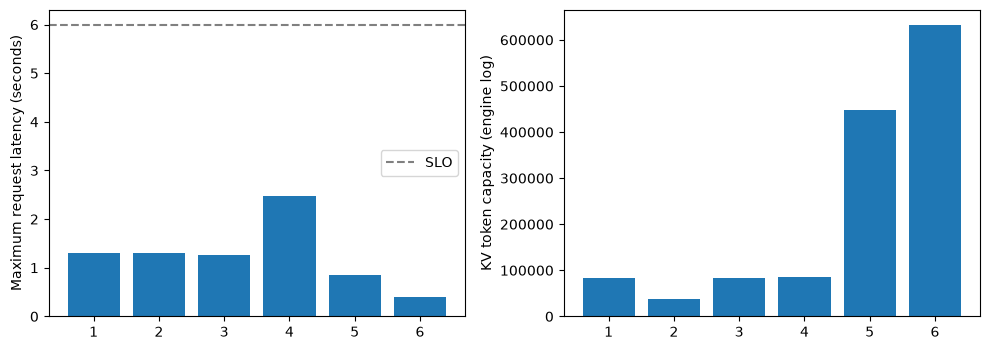

1 A 기준 Qwen/Qwen2.5-32B-Instruct-AWQ
2 A 비율 낮춤 Qwen/Qwen2.5-32B-Instruct-AWQ
3 B max_model_len 32768 Qwen/Qwen2.5-32B-Instruct-AWQ
4 C max_num_seqs 4 Qwen/Qwen2.5-32B-Instruct-AWQ
5 D 7B 16비트 Qwen/Qwen2.5-7B-Instruct
6 D 직접 만든 7B AWQ /workspace/results/d56/7b-awq-ko


In [41]:
import numpy as np
import matplotlib.pyplot as plt
valid=[(label,row) for label,row in TEAM_ROWS.items() if "최대 지연 초" in row]
if valid:
    x=np.arange(len(valid));fig,axes=plt.subplots(1,2,figsize=(10,3.6))
    axes[0].bar(x,[row["최대 지연 초"] for label,row in valid])
    axes[0].axhline(TARGET_SECONDS,color="gray",linestyle="--",label="SLO")
    axes[0].set(xticks=x,xticklabels=range(1,len(valid)+1),ylabel="Maximum request latency (seconds)")
    axes[0].legend()
    axes[1].bar(x,[row.get("kv_tokens",np.nan) or np.nan for label,row in valid])
    axes[1].set(xticks=x,xticklabels=range(1,len(valid)+1),ylabel="KV token capacity (engine log)")
    fig.tight_layout();fig.savefig(RESULTS/"d57_team_comparison.png",dpi=85);plt.show()
    for i,(label,row) in enumerate(valid,1):print(i,label,row["모델"])

## Step 6. 동시 요청 수에 따른 측정과 팀 결과표

교재 : 2.4.2 확장성, 9.8 고급 프레임워크 ZeRO와 DeepSpeed

Step 5의 다섯 행을 팀 결과표 한 장으로 모읍니다. 표를 보고 팀이 서비스 설정을 정한 뒤 그 설정으로 서버를 다시 기동해 동시 요청 수를 1개부터 30개까지 늘려 갑니다.

**실행 큐의 최고값이 동시 요청 수를 따라 올라가면 연속 배칭이 요청들을 한 배치로 계산하고 있습니다.**

In [42]:
import pandas as pd

COLS = ["역할", "설정", "모델", "비율", "max_model_len", "weights_gib", "kv_tokens", "max_concurrency", "start_sec",
        "혼자 초당 토큰", "최대 지연 초", "정답", "최고 실행 큐", "최고 대기 큐", "최고 KV", "backend", "kernels", "오류"]
table = pd.DataFrame([{c: r.get(c) for c in COLS} for r in TEAM_ROWS.values()])
if AVG_PAGES:                 # 우리 질문 길이로 다시 계산한 동시 요청 수(이론 노트 3.4절)
    table["우리 요청 기준 동시 수"] = pd.to_numeric(table["kv_tokens"]) // (AVG_PAGES * 16)
display(table.fillna("-"))
table.to_csv(RESULTS / "d57_team_table.csv", index=False, encoding="utf-8-sig")
# 엔진 교체의 영향(이론 노트 6.3절)
d_row = TEAM_ROWS.get("D 7B 16비트", {})
if "correct" in d_row:
    print("transformers 7B 대비 vLLM 7B :", count_flips(results["transformers 16비트 한 명씩"]["correct"], d_row["correct"]))

,역할,설정,모델,비율,max_model_len,weights_gib,kv_tokens,max_concurrency,start_sec,혼자 초당 토큰,최대 지연 초,정답,최고 실행 큐,최고 대기 큐,최고 KV,backend,kernels,오류,우리 요청 기준 동시 수
0,A,기준,Qwen/Qwen2.5-32B-Instruct-AWQ,0.92,4096,18.14,82704.0,20.19,115.6,15.4,1.31,26,7.0,0.0,0.006579,FLASH_ATTN,[MarlinLinearKernel for AutoAWQMarlinLinearMet...,-,654.0
1,A,비율 낮춤,Qwen/Qwen2.5-32B-Instruct-AWQ,0.65,4096,18.14,38144.0,9.31,85.2,15.4,1.31,26,7.0,0.0,0.014268,FLASH_ATTN,[MarlinLinearKernel for AutoAWQMarlinLinearMet...,-,301.0
2,B,max_model_len 32768,Qwen/Qwen2.5-32B-Instruct-AWQ,0.92,32768,18.14,82704.0,2.52,118.6,15.6,1.27,26,9.0,0.0,0.009288,FLASH_ATTN,[MarlinLinearKernel for AutoAWQMarlinLinearMet...,-,654.0
3,C,max_num_seqs 4,Qwen/Qwen2.5-32B-Instruct-AWQ,0.92,4096,18.14,86160.0,21.04,85.2,14.2,2.48,26,4.0,11.0,0.003715,FLASH_ATTN,[MarlinLinearKernel for AutoAWQMarlinLinearMet...,-,681.0
4,D,7B 16비트,Qwen/Qwen2.5-7B-Instruct,0.92,4096,14.29,447168.0,109.17,115.9,22.9,0.86,23,7.0,0.0,0.000966,FLASH_ATTN,[],-,3537.0
5,D,직접 만든 7B AWQ,/workspace/results/d56/7b-awq-ko,0.92,4096,5.29,633248.0,154.60,85.1,47.4,0.39,26,0.0,0.0,0.000000,FLASH_ATTN,[MarlinLinearKernel for AutoAWQMarlinLinearMet...,-,5009.0


transformers 7B 대비 vLLM 7B : {'맞→틀': 0, '틀→맞': 0}


**팀 결과표를 읽고 서비스 설정을 정합니다.**

1. **오류 열** : 기동하지 못한 행은 오류 문장을 이론 노트 4.4절의 순서로 읽습니다
2. **kv_tokens와 우리 요청 기준 동시 수** : A의 두 행, D의 행을 비교해 비율과 모델이 KV 블록을 얼마나 바꾸는지 봅니다
3. **최고 대기 큐와 최대 지연 초** : C의 행에서 한도가 대기 큐를 만드는지 봅니다
4. **정답** : 32B 4비트와 7B 16비트의 차이가 KV 블록을 덜 받는 값어치가 있는지 판단합니다

정한 값을 아래 셀의 `TEAM_UTIL`, `TEAM_SEQS`에 적습니다. 비워 두면 기준 서버와 같은 설정입니다.

In [43]:
TEAM_UTIL = os.environ.get("D57_TEAM_UTIL")          # 예 : "0.90"
TEAM_SEQS = os.environ.get("D57_TEAM_SEQS")          # 예 : "32"
LEVELS = [int(x) for x in os.environ.get("D57_LEVELS", "1,2,4,8,16,30").split(",")]
LOAD = []
stop_all()
srv = start_server("team", MODEL_ID, float(TEAM_UTIL) if TEAM_UTIL else decide_util()[0],
                   extra=("--max-num-seqs", TEAM_SEQS) if TEAM_SEQS else ())
if "error" in srv:
    print("기동 실패 :", srv["error"])
else:
    client = make_client(srv)
    ask_server(client, QUESTIONS[0])                            # 예열
    for n in LEVELS:
        with MetricsWatcher(srv["base"]) as w:
            r = run_load(client, n)
        LOAD.append({**r, "최고": dict(w.peak)})
        print(n, {k: v for k, v in r.items() if k != "rows"}, w.peak)

1 {'동시': 1, '경과 초': 10.18, '초당 질문': 2.95, '가장 늦은 사람 초': 0.95, '실패': 0} {'실행 줄': 1.0, '대기 줄': 0.0, 'KV 사용률': 0.001833516685001868}
2 {'동시': 2, '경과 초': 5.52, '초당 질문': 5.43, '가장 늦은 사람 초': 0.94, '실패': 0} {'실행 줄': 2.0, '대기 줄': 0.0, 'KV 사용률': 0.0025669233590025486}
4 {'동시': 4, '경과 초': 2.87, '초당 질문': 10.44, '가장 늦은 사람 초': 0.96, '실패': 0} {'실행 줄': 4.0, '대기 줄': 0.0, 'KV 사용률': 0.004033736707004021}
8 {'동시': 8, '경과 초': 1.57, '초당 질문': 19.16, '가장 늦은 사람 초': 1.0, '실패': 0} {'실행 줄': 7.0, '대기 줄': 0.0, 'KV 사용률': 0.005867253392005889}
16 {'동시': 16, '경과 초': 1.27, '초당 질문': 23.63, '가장 늦은 사람 초': 0.97, '실패': 0} {'실행 줄': 7.0, '대기 줄': 0.0, 'KV 사용률': 0.006233956729006285}
30 {'동시': 30, '경과 초': 1.19, '초당 질문': 25.11, '가장 늦은 사람 초': 1.12, '실패': 0} {'실행 줄': 7.0, '대기 줄': 0.0, 'KV 사용률': 0.006233956729006285}


In [44]:
if LOAD:
    top = LOAD[-1]
    record(f"vLLM 32B 4비트 서버 동시 {top['동시']}",
           [{**x, "done_at": x["sec"]} for x in top["rows"]], top["경과 초"], "vLLM 서버",
           load=[{k: v for k, v in r.items() if k != "rows"} for r in LOAD], team_util=TEAM_UTIL, team_seqs=TEAM_SEQS)
    # SLO 안에 실패 없이 답한 가장 큰 동시 요청 수(서빙 프로젝트 4.1절)
    VLLM_LIMIT = max([r["동시"] for r in LOAD if r["가장 늦은 사람 초"] <= TARGET_SECONDS and not r["실패"]], default=0)
    HF_ONE = hf_wall / len(QUESTIONS)               # 요청이 한 줄로 서는 서버의 어림 계산(로컬 GPU 배포 실습 노트 부록 실습 G) : n x 단일 요청 시간
    results["용량"] = {"SLO 초": TARGET_SECONDS, "vLLM 응답 시간 기준": VLLM_LIMIT,
                     "transformers 어림": int(TARGET_SECONDS // HF_ONE),
                     "VRAM 기준": int(eng["num_gpu_blocks"] / AVG_PAGES) if AVG_PAGES and eng.get("num_gpu_blocks") else None}
    save_results()
    print(results["용량"])

[vLLM 32B 4비트 서버 동시 30] {'정답': 26, '경과 초': 1.19, '생성 토큰': 248, '초당 토큰': 208.4, '가장 늦은 사람 초': 1.12}
{'SLO 초': 6.0, 'vLLM 응답 시간 기준': 30, 'transformers 어림': 23, 'VRAM 기준': 650}


**두 팀의 표를 나란히 놓을 준비를 합니다.** 결과표 CSV와 `d57_results.json`의 `_conditions`에 GPU 이름과 버전이 함께 남아 있습니다. GPU가 다른 팀끼리는 경과 시간을 직접 비교하지 않고 kv_tokens, 응답 시간 기준 동시 수, 정답 수처럼 설정과 모델이 정하는 값부터 비교합니다(이론 노트 6.4절).

## Step 7. 서빙 프로젝트 서버의 생성 백엔드를 vLLM으로 교체

**담당 B·C.** 서빙 프로젝트(52일차) 서버의 `app/model_service.py`에서 `generate_reply` 안만 vLLM의 OpenAI 호환 주소 호출로 바꿉니다. 인자와 반환 키(`response`, `turn_count`, `elapsed_ms`, `model_version`)는 그대로라서 `main.py`, `auth.py`, `schemas.py`는 고치지 않습니다. 주소와 모델 이름은 환경 변수 `VLLM_BASE_URL`, `MODEL_ID`로 받습니다.

B는 파일을 바꾸고 서버를 기동하며 C는 52일차의 채점 항목을 실행합니다. Step 6의 vLLM 서버가 기동되어 있어야 합니다.

In [45]:
PROJ = Path(os.environ.get("D57_PROJECT_DIR", "/workspace/serving_project_d57"))
(PROJ / "app").mkdir(parents=True, exist_ok=True)
print("D57 전용 프로젝트:", PROJ)

D57 전용 프로젝트: /workspace/serving_project_d57


D53을 실행하지 않았어도 아래 준비 코드가 같은 요청·응답 규격의 API 파일을 제공합니다. D57 전용 폴더에 저장하므로 이전 프로젝트를 덮어쓰지 않습니다. 외부 `/chat`의 네 필드는 `success`, `response`, `model_name`, `user`이고, 내부 생성 함수의 측정용 네 필드와 구분합니다.

In [46]:
# app/auth.py
file_body = r'''
import json,os
from fastapi import Header,HTTPException

async def verify_api_key(x_api_key: str | None = Header(default=None)) -> str:
    keys=json.loads(os.environ.get("CHATBOT_API_KEYS",'{"test-key-001":"학습자"}'))
    if not x_api_key or x_api_key not in keys:
        raise HTTPException(status_code=401,detail="유효한 API 키가 필요합니다.")
    return keys[x_api_key]
'''
p=PROJ/'app/auth.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text(file_body,encoding='utf-8')

364

In [47]:
# app/chatbot_schemas.py
file_body = r'''
from typing import Literal
from pydantic import BaseModel,Field,model_validator

class Message(BaseModel):
    role: Literal["user","bot","assistant"]
    content: str = Field(...,min_length=1,max_length=1000)

class ChatRequest(BaseModel):
    messages: list[Message] = Field(...,min_length=1)
    max_new_tokens: int = Field(default=100,ge=10,le=500)
    temperature: float = Field(default=0.8,gt=0.0,le=2.0)

    @model_validator(mode="after")
    def last_message_is_user(self):
        if self.messages[-1].role!="user":
            raise ValueError("마지막 메시지는 사용자의 질문이어야 합니다.")
        return self

class ChatResponse(BaseModel):
    success: bool
    response: str
    model_name: str
    user: str | None = None
'''
p=PROJ/'app/chatbot_schemas.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text(file_body,encoding='utf-8')

720

In [48]:
# app/errors.py
file_body = r'''
import logging
from fastapi import Request
from fastapi.responses import JSONResponse

class InputTooLongError(ValueError):
    pass

def register_error_handlers(app):
    @app.exception_handler(InputTooLongError)
    async def too_long(request: Request,exc: InputTooLongError):
        return JSONResponse(status_code=413,content={"detail":str(exc)})

    @app.exception_handler(Exception)
    async def unexpected(request: Request,exc: Exception):
        logging.getLogger("chatbot").error("생성 오류",exc_info=True)
        return JSONResponse(status_code=500,content={"detail":"서버 내부 오류가 발생했습니다."})
'''
p=PROJ/'app/errors.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text(file_body,encoding='utf-8')

601

In [49]:
# app/chatbot_api.py
file_body = r'''
import asyncio, os
from contextlib import asynccontextmanager
from concurrent.futures import ThreadPoolExecutor
from fastapi import Depends,FastAPI
from app.auth import verify_api_key
from app.chatbot_schemas import ChatRequest,ChatResponse
from app.errors import register_error_handlers
from app.model_service import MODEL_VERSION,generate_reply

@asynccontextmanager
async def lifespan(app):
    app.state.executor=ThreadPoolExecutor(max_workers=max(1, int(os.environ["MAX_WORKERS"])))
    try:yield
    finally:app.state.executor.shutdown(wait=True)

app=FastAPI(title="D53 Chatbot",version=MODEL_VERSION,lifespan=lifespan)
register_error_handlers(app)

@app.get("/health")
async def health():
    return {"status":"healthy","model":MODEL_VERSION}

@app.post("/chat",response_model=ChatResponse)
async def chat(req: ChatRequest,user: str = Depends(verify_api_key)):
    messages=[m.model_dump() for m in req.messages]
    result=await asyncio.get_running_loop().run_in_executor(
        app.state.executor,generate_reply,messages,req.max_new_tokens,req.temperature)
    return ChatResponse(success=True,response=result["response"],
                        model_name=result["model_version"].split("@")[0],user=user)
'''
p=PROJ/'app/chatbot_api.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text(file_body,encoding='utf-8')

1220

In [50]:
# app/main.py
file_body = r'''
# uvicorn app.main:app으로도 실행할 수 있는 진입점입니다.
from app.chatbot_api import app
'''
p=PROJ/'app/main.py'
p.parent.mkdir(parents=True,exist_ok=True)
p.write_text(file_body,encoding='utf-8')

76

In [51]:
(PROJ/"app"/"__init__.py").touch()

In [52]:
# vLLM을 호출하는 생성 함수
service_body = r'''
"""추론 서비스 모듈 (57일차 : generate_reply 안만 vLLM 호출로 바꿈)"""
import os
import time

import httpx

MODEL_VERSION = os.environ.get("MODEL_VERSION", "chatbot-v1.0")
VLLM_BASE_URL = os.environ.get("VLLM_BASE_URL", "http://127.0.0.1:8570")
MODEL_ID = os.environ.get("MODEL_ID", "team-llm")          # vLLM 의 --served-model-name 과 같은 값
VLLM_API_KEY = os.environ.get("VLLM_API_KEY", "")
SYSTEM = os.environ.get("SYSTEM_PROMPT", "답변은 반드시 한국어로만 작성하세요.")
ROLE = {"user": "user", "bot": "assistant", "assistant": "assistant"}   # 52일차 스키마는 bot 도 받습니다


def generate_reply(messages: list[dict], max_new_tokens: int = 64, temperature: float = 0.7) -> dict:
    """52일차와 같은 인자와 반환 키"""
    t0 = time.perf_counter()
    if messages[-1]["content"] == "__TRIGGER_500_ERROR__":     # 52일차 채점 8번 항목
        raise RuntimeError("Internal GPU tensor allocation failed at /app/secret_path/model.py:142")
    body = {"model": MODEL_ID, "max_tokens": max_new_tokens, "temperature": temperature,
            "messages": [{"role": "system", "content": SYSTEM}]
            + [{"role": ROLE[m["role"]], "content": m["content"]} for m in messages]}
    r = httpx.post(VLLM_BASE_URL + "/v1/chat/completions", json=body, timeout=120,
                   headers={"Authorization": f"Bearer {VLLM_API_KEY}"})
    r.raise_for_status()        # 실패는 main.py 의 예외 처리기가 500 으로 바꾸고 내용은 숨깁니다
    return {"response": r.json()["choices"][0]["message"]["content"],
            "turn_count": (len(messages) + 1) // 2,
            "elapsed_ms": round((time.perf_counter() - t0) * 1000, 1),
            "model_version": MODEL_VERSION}'''
(PROJ / 'app' / 'model_service.py').write_text(service_body,encoding='utf-8')

1582

In [53]:
if "VLLM_LIMIT" not in globals() or VLLM_LIMIT < 1:
    raise RuntimeError("SLO를 만족한 동시 요청 수가 없습니다. Step 6 설정과 결과를 먼저 확인하세요.")
import requests

API_BASE = f"http://127.0.0.1:{pick_port(8000, 8010)}"
# MAX_WORKERS는 Step 6의 측정값입니다(이론 노트 4.5절)
api_env = {**os.environ, "VLLM_BASE_URL": srv["base"], "MODEL_ID": SERVED_NAME, "VLLM_API_KEY": VLLM_KEY,
           "CHATBOT_API_KEYS": json.dumps({"test-key-001":"학습자"}, ensure_ascii=False), "MODEL_VERSION": "vllm-" + MODEL_ID.split("/")[-1],
           "MAX_WORKERS": str(int(VLLM_LIMIT))}
api = subprocess.Popen([sys.executable, "-m", "uvicorn", "app.main:app", "--host", "127.0.0.1",
                        "--port", API_BASE.rsplit(":", 1)[1]], cwd=PROJ, env=api_env,
                       stdout=open(WORK / "serving_project.log", "w"), stderr=subprocess.STDOUT)
for _ in range(60):
    if api.poll() is not None:raise RuntimeError("API가 종료됐습니다. serving_project.log를 확인하세요.")
    try:
        health=requests.get(API_BASE+"/health",timeout=1)
        if health.status_code==200:break
    except requests.RequestException:pass
    time.sleep(.5)
else:raise RuntimeError("API 기동 대기 시간이 지났습니다.")
print("서빙 프로젝트 /health:",health.json())

서빙 프로젝트 /health: {'status': 'healthy', 'model': 'vllm-Qwen2.5-32B-Instruct-AWQ'}


**의도적인 오류 검사 안내:** 마지막 요청은 내부 오류를 일부러 발생시킵니다. 서버 로그에 traceback이 보여도 응답이 500이고 내부 경로가 응답 본문에 없으면 통과입니다. 정상 요청의 실제 실패와 이 검사 요청을 구분합니다.

In [54]:
H = {"X-API-Key": "test-key-001"}
ONE = {"messages": [{"role": "user", "content": "재택근무는 주 며칠까지 신청할 수 있습니까?"}]}
MULTI = {"messages": [{"role": "user", "content": "서울 날씨 어때?"}, {"role": "bot", "content": "맑고 선선합니다."},
                      {"role": "user", "content": "그럼 옷은 어떻게 입을까?"}]}
KEYS = {"success", "response", "model_name", "user"}
# 52일차 3절의 8항목. 3번의 '이전 질문 문구 포함'은 흉내 함수 전용 조건이라 뺐습니다
CHECKS = [
    (1, "헬스체크", None, {}, lambda r: r.status_code == 200 and r.json().get("status") == "healthy"),
    (2, "싱글턴 200, 응답 키", ONE, H, lambda r: r.status_code == 200 and set(r.json()) == KEYS),
    (3, "멀티턴 200, 응답 규격", MULTI, H, lambda r: r.status_code == 200 and set(r.json()) == KEYS and r.json().get("success") is True),
    (4, "키 누락 401", ONE, {}, lambda r: r.status_code == 401),
    (5, "잘못된 키 401", ONE, {"X-API-Key": "wrong-key"}, lambda r: r.status_code == 401),
    (6, "빈 메시지 422", {"messages": []}, H, lambda r: r.status_code == 422),
    (7, "온도 5.0 422", {**ONE, "temperature": 5.0}, H, lambda r: r.status_code == 422),
    (8, "500 내부 정보 비노출", {"messages": [{"role": "user", "content": "__TRIGGER_500_ERROR__"}]}, H,
     lambda r: r.status_code == 500 and "Traceback" not in r.text and "secret_path" not in r.text),
]
GRADE = {}
for no, name, body, headers, ok in CHECKS:
    r = (requests.get(API_BASE + "/health", timeout=5) if body is None
         else requests.post(API_BASE + "/chat", json=body, headers=headers, timeout=120))
    GRADE[f"{no} {name}"] = ok(r)
    print(no, "PASS" if ok(r) else "FAIL", name, r.status_code, r.text[:80])
results["52일차 채점"] = GRADE
save_results()
print(f"{sum(GRADE.values())} / {len(GRADE)} 항목 통과")

1 PASS 헬스체크 200 {"status":"healthy","model":"vllm-Qwen2.5-32B-Instruct-AWQ"}


2 PASS 싱글턴 200, 응답 키 200 {"success":true,"response":"재택근무의 가능 일수는 회사 정책에 따라 다르므로, 정확한 답변을 위해서는 귀하의 회사 규정을
3 PASS 멀티턴 200, 응답 규격 200 {"success":true,"response":"서울의 현재 날씨가 맑고 선선하다면,얇은 가디건이나 셔츠를 입는게 좋을 것 같아요. 아침과 저
4 PASS 키 누락 401 401 {"detail":"유효한 API 키가 필요합니다."}
5 PASS 잘못된 키 401 401 {"detail":"유효한 API 키가 필요합니다."}
6 PASS 빈 메시지 422 422 {"detail":[{"type":"too_short","loc":["body","messages"],"msg":"List should have
7 PASS 온도 5.0 422 422 {"detail":[{"type":"less_than_equal","loc":["body","temperature"],"msg":"Input s
8 PASS 500 내부 정보 비노출 500 {"detail":"서버 내부 오류가 발생했습니다."}
8 / 8 항목 통과


**8항목이 모두 PASS여야 합니다.** 외부 응답 네 필드와 인증·검증·오류 비노출을 확인한 결과입니다. 생성 시간은 서버 부하 측정에서 확인하며 API 응답 필드로 노출하지 않습니다.

**로컬 작업 : 팀 Pod의 터미널에서 같은 구성을 기동하는 순서**

1. vLLM은 자기 가상환경에 둡니다. 서빙 프로젝트의 서버와 한 환경에 설치하지 않습니다(4장 심화 ‘vLLM을 따로 두는 환경’)
2. Step 6에서 측정한 응답 시간 기준 동시 요청 수를 `--max-num-seqs`, `MAX_WORKERS`, 게이트웨이가 아는 슬롯 수에 같은 값으로 적습니다(이론 노트 5.3절)
3. 두 서버 모두 `127.0.0.1`에만 엽니다. 외부에 공개할 포트는 게이트웨이 하나입니다

```bash
# vLLM 서버. 키는 환경 변수로 넣습니다
HF_HOME=/workspace/hf VLLM_NO_USAGE_STATS=1 VLLM_API_KEY="$VLLM_KEY" \
vllm serve Qwen/Qwen2.5-32B-Instruct-AWQ --served-model-name team-llm \
    --max-model-len 4096 --max-num-seqs <측정한 값> --host 127.0.0.1 --port 8570

# 서빙 프로젝트 서버 : model_service.py 만 바꾼 뒤 52일차와 같은 명령으로 기동합니다
cd /workspace/serving_project && VLLM_BASE_URL=http://127.0.0.1:8570 MODEL_ID=team-llm VLLM_API_KEY="$VLLM_KEY" \
MAX_WORKERS=<측정한 값> CHATBOT_API_KEYS='{"test-key-001":"학습자"}' uvicorn app.main:app --host 127.0.0.1 --port 8000
```

In [55]:
api.terminate()      # 담당 B : 서빙 프로젝트 서버 종료. vLLM 서버는 트랙에서 쓰므로 공유와 정리에서 종료합니다

## Step 8. 선택 심화 트랙

두 트랙 중 **하나를 골라** 팀이 함께 수행하고 공유합니다. 트랙마다 서버를 한두 번 더 기동하므로 Step 7까지 마친 뒤 시작합니다.

<div style="font-size: 18px; line-height: 1.6;">

| 트랙 | 주제 | 성격 | 난이도 |
|---|---|---|---|
| 1 | 긴 입력과 max_model_len | 측정 | 중 |
| 2 | 에어갭 RAG 노트 LLM 서버의 vLLM 교체 | 운영 | 중 |

</div>

#### 트랙 1. 긴 입력과 max_model_len

벤치마크 하네스의 규정 문장들을 이어 붙여 입력을 256, 1,000, 3,000토큰으로 만들고 동시 요청 8개로 보내 첫 청크 시간을 측정합니다. 32B는 입력 토큰 하나의 KV 캐시가 256KiB라서 3,000토큰 입력 여덟 개면 KV 캐시 6GiB 남짓을 씁니다(계산).

In [56]:
RULES = [q["q"].split("규정 : ")[1].split("\n")[0] for q in QUESTIONS if q["type"] == "지문"]


def long_context(n_tok):
    lines, i = [], 0
    while n_tokens("\n".join(lines)) < n_tok:
        lines.append(f"제{i + 1}조 {RULES[i % len(RULES)]}")
        i += 1
    return "\n".join(lines)


def first_piece_sec(client, context, question="재택근무는 주 며칠까지 신청할 수 있습니까?"):
    """스트리밍으로 보내고 첫 청크까지의 시간(초). 실패는 문자열"""
    t0 = time.perf_counter()
    try:
        stream = client.chat.completions.create(
            model=SERVED_NAME, temperature=0.0, max_tokens=32, stream=True,
            messages=conv({"q": f"근거 문서 :\n{context}\n\n질문 : {question}"}))
        for chunk in stream:
            if chunk.choices and chunk.choices[0].delta.content:
                return time.perf_counter() - t0
        return "청크 없음"
    except Exception as e:
        return type(e).__name__

In [57]:
# 실습 : 길이마다 동시 요청 8개로 first_piece_sec을 호출하고 가장 늦은 첫 청크 시간을 표로 출력하세요
LONG = {}
stop_all()
s2 = start_server("t1_long", MODEL_ID, decide_util()[0])
c2 = make_client(s2)
for n in [256, 1000, 3000]:
    ctx = long_context(n)
    with ThreadPoolExecutor(max_workers=8) as ex:
        ### START CODE HERE ### (같은 입력으로 요청 8개가 동시에 first_piece_sec 호출하기 1줄)
        # 1) ex.map 으로 first_piece_sec(c2, ctx) 를 8번 호출하고 결과를 목록으로 모읍니다
        outs = list(ex.map(lambda _: first_piece_sec(c2, ctx), range(8)))
        ### END CODE HERE ###
    secs = [o for o in outs if isinstance(o, float)]
    LONG[n] = {"입력 토큰": n_tokens(ctx), "가장 늦은 첫 청크 초": round(max(secs), 2) if secs else None,
               "실패": len(outs) - len(secs)}
    print(n, LONG[n])
print("길이 상한을 넘은 입력 :", first_piece_sec(c2, long_context(MAX_MODEL_LEN + 500)))
print(stop_server(s2))

team 종료 : 남은 GPU 메모리 44.1 GiB
256 {'입력 토큰': 278, '가장 늦은 첫 청크 초': 0.46, '실패': 0}
1000 {'입력 토큰': 1004, '가장 늦은 첫 청크 초': 0.67, '실패': 0}
3000 {'입력 토큰': 3000, '가장 늦은 첫 청크 초': 1.57, '실패': 0}
길이 상한을 넘은 입력 : BadRequestError
종료 : 남은 GPU 메모리 44.1 GiB


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
outs = list(ex.map(lambda _: first_piece_sec(c2, ctx), range(8)))
```

**입력이 길수록 첫 청크가 늦어집니다.**

</details>

#### 트랙 2. 에어갭 RAG 노트 LLM 서버의 vLLM 교체

에어갭 RAG 노트의 LLM 서버는 저장소 이름 대신 경로로 모델을 로드하고 외부 통신을 막았습니다. 같은 일을 vLLM 서버로 합니다. 볼륨의 캐시 폴더를 그대로 반입할 폴더로 씁니다.

In [58]:
from huggingface_hub import snapshot_download

LOCAL_MODEL = Path(snapshot_download(MODEL_ID, local_files_only=True))   # 볼륨에 있는 파일만 씁니다
stop_all()
os.environ["HF_HUB_OFFLINE"] = "1"                        # 여기부터는 허브에 묻지 않습니다
s3 = start_server("t2_airgap", LOCAL_MODEL, decide_util()[0])
os.environ.pop("HF_HUB_OFFLINE")
LLM_URL = s3.get("base")
print(LOCAL_MODEL, s3.get("error") or f"{LLM_URL} ({s3['start_sec']}초)")

/workspace/.cache/huggingface/hub/models--Qwen--Qwen2.5-32B-Instruct-AWQ/snapshots/5c7cb76a268fc6cfbb9c4777eb24ba6e27f9ee6c http://127.0.0.1:8570 (115.4초)


In [59]:
import requests

# 에어갭 RAG 노트의 오케스트레이터가 보내던 본문 그대로입니다
body = {"messages": [{"role": "system", "content": SYSTEM},
                     {"role": "user", "content": "[규정]\n재택근무는 주 2일까지 신청할 수 있다.\n\n질문: 재택근무는 주 며칠까지 돼?"}],
        "max_tokens": 400}

# 실습 : 그 노트의 호출 한 줄을 vLLM 서버에 맞게 고치세요
### START CODE HERE ### (키를 실은 헤더와 온도 정하기 2줄)
# 1) 키를 Authorization 헤더에 Bearer 로 실어 보냅니다
HEADERS = {"Authorization": f"Bearer {VLLM_KEY}"}
# 2) temperature 도 직접 적습니다(이론 노트 4.1절)
body["temperature"] = 0.0
### END CODE HERE ###
if LLM_URL:
    r = requests.post(f"{LLM_URL}/v1/chat/completions", json=body, timeout=180, headers=HEADERS)
    print(r.status_code, r.text[:200])

200 {"id":"chatcmpl-8880f116ed4b7112","object":"chat.completion","created":1794388138,"model":"team-llm","choices":[{"index":0,"message":{"role":"assistant","content":"주 2일까지 가능합니다.","refusal":null,"annot


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
HEADERS = {"Authorization": f"Bearer {VLLM_KEY}"}
body["temperature"] = 0.0
```

**주소, 키, 온도가 바뀌었습니다.** 그 노트의 서버는 온도를 받지 못하면 0.2로 정했지만 vLLM 서버는 저장소의 생성 설정에 적힌 온도로 샘플링합니다.

</details>

In [60]:
if "error" not in s3:
    print(stop_server(s3))

종료 : 남은 GPU 메모리 44.1 GiB


**로컬 작업** : 폐쇄망 서버에서는 모델 폴더와 vLLM 설치 파일을 함께 반입합니다.

## Step 9. 공유와 정리

팀 결과표를 들고 두 팀이 함께 공유합니다.

**1. 팀 결과표** : Step 6의 표에서 역할마다 바꾼 설정 하나와 바뀐 값(kv_tokens, 최대 지연, 최고 대기 큐), GPU 이름과 백엔드, 커널 이름

**2. 두 팀 비교** : 두 팀의 표를 나란히 놓고 같은 설정에서 kv_tokens와 응답 시간 기준 동시 수가 어떻게 다른지 한 문단으로 적습니다. GPU가 다르면 그 차이부터 적습니다

**3. 응답 시간 기준 동시 요청 수** : Step 6에서 SLO 안에 든 가장 큰 동시 요청 수, 우리 요청 길이로 계산한 메모리 기준 동시 수, 둘 중 작은 값

**4. 서빙 프로젝트 채점** : Step 7의 8항목 결과와 `MAX_WORKERS`에 적은 값

**5. 선택한 트랙의 결과** : 얻은 판단 하나와 판단을 뒷받침한 측정값

**Pod 종료 점검표** (RunPod 일차마다 마지막에 합니다)

1. 아래 셀로 vLLM 서버, 오프라인 엔진, 서빙 프로젝트 서버를 모두 종료합니다
2. 셀이 출력한 `nvidia-smi` 프로세스 목록이 비어 있는지 봅니다
3. `/workspace/results/d57`에 `d57_results.json`과 `d57_team_table.csv`가 있는지 보고 제출용으로 내려받습니다
4. RunPod 콘솔에서 Pod를 종료(terminate)합니다. 네트워크 볼륨의 모델과 결과는 남고 컨테이너 디스크는 지워집니다
5. 볼륨 사용량을 적어 둡니다. 볼륨은 71일차 경량화 파이프라인까지 같이 씁니다. 사용 시간과 비용은 RunPod 콘솔과 요금표에서 확인합니다

In [61]:
# 기동한 서버와 엔진을 모두 종료합니다. Pod를 종료하기 전에 실행하세요
stop_all()
if "llm" in globals().get("eng", {}):
    print(stop_llm(eng))
if globals().get("api") is not None:
    api.terminate()
save_results()
print("결과 :", sorted(p.name for p in RESULTS.iterdir()))
!nvidia-smi --query-compute-apps=pid,used_memory --format=csv
!du -sh /workspace/hf /workspace/results

결과 : ['d57_results.json', 'd57_team_comparison.png', 'd57_team_table.csv']
pid, used_gpu_memory [MiB]
2265, 342 MiB


du: cannot access '/workspace/hf': No such file or directory
27G	/workspace/results


### 혼자 설명하기

서버는 실행되지만 요청이 몰리면 응답 시간 목표를 넘습니다. GPU 메모리 사용 비율·입력과 답을 합친 최대 길이·동시 처리 수 중 먼저 바꿀 설정 하나를 고르고, 직접 측정한 응답 시간과 대기 요청 수로 이유를 설명합니다.

| 자기 점검 | 남길 근거 |
|---|---|
| [목표 1] 바꾸고 실행한 내용 | 사용한 입력과 설정, 실제 출력 |
| [목표 2] 비교한 결과와 판단 | 그대로 둔 설정과 바꾼 설정, 직접 측정한 결과인지 여부 |
| [목표 3] 다시 실행할 때 필요한 기록 | 저장한 파일과 선택에 사용한 측정값 |

D58에서는 동시 요청 수를 늘리며 처리량과 응답 시간이 어떻게 달라지는지 그립니다. 그 결과로 실제 서비스에서 허용할 동시 요청 수를 정합니다.

## 마무리 과제. vLLM 도입 판단서

팀이 가정한 사내 서비스를 vLLM으로 옮길지 정하고 판단서를 씁니다. 판단서에는 역할표(누가 어느 셀을 실행했는지)를 함께 붙입니다.

**1단계. 서비스 조건**

1. 가장 긴 입력과 가장 긴 답, 응답 시간 SLO, 피크 시간의 동시 사용자 수를 적습니다
2. 같은 GPU를 함께 쓰는 프로그램과 사람을 적습니다. 함께 쓴다면 메모리 비율을 어떻게 나눌지 운영 규칙을 적습니다

**2단계. 설정과 기동 기록**

3. 이론 노트 5.4절의 순서대로 `max_model_len`, `gpu_memory_utilization`, `max_num_seqs`를 정하고 값마다 팀 결과표의 근거를 한 줄씩 적습니다
4. 기동 로그에서 백엔드, 커널, 가중치, KV 캐시 토큰 수, 기동 시간을 옮기고 우리 요청 길이로 메모리 기준 동시 요청 수를 계산합니다

**3단계. 부하**

5. 동시 요청 1개부터 피크 사용자 수까지 처리량과 최대 지연 시간을 표로 적습니다
6. "메모리 기준 N명, 응답 시간 기준 M명, 따라서 M명으로 엽니다"의 형식으로 결론을 씁니다(서빙 프로젝트 4.1절). transformers로 하나씩 처리하는 서버의 값도 나란히 적습니다

**4단계. 모델과 연결**

7. 32B 4비트와 7B 16비트 가운데 무엇을 서빙할지 정합니다. 정답 수와 KV 토큰을 근거로 듭니다
8. 게이트웨이가 아는 슬롯 수, 서버의 `MAX_WORKERS`, vLLM의 `max_num_seqs`를 같은 값으로 적고 헬스체크 응답을 어떻게 변환하는지 적습니다

**평가 기준**

vLLM을 쓰기로 했는지보다 **근거와 재현**을 봅니다.

## 부록 실습 A. vLLM으로 로드한 7B 4비트 파일 측정

본 실습을 마친 뒤 시간이 남거나 더 깊이 보고 싶을 때 하는 실습입니다. 본 실습 Step 7까지 실행한 상태에서 시작합니다.

GPTQ·AWQ 노트에서 만든 7B GPTQ, AWQ, compressed-tensors 파일과 Qwen 팀의 7B 공식 4비트 파일을 vLLM 서버로 하나씩 로드합니다. 행마다 기동 로그에서 커널 이름, 가중치 메모리, KV 캐시 토큰 수를 읽고 30문항을 하나씩, 한꺼번에 보냅니다. 4비트 행의 flip은 같은 엔진의 16비트 행(Step 5의 D 행)과 비교해 셉니다.

In [62]:
# 실습 : 앞 노트에서 만든 폴더가 있으면 그 폴더를, 없으면 공개 저장소 이름을 고르는 함수를 완성하세요
# 반환값 : (경로 또는 저장소 이름, "GPTQ·AWQ 노트 폴더" 또는 "공개 저장소" 또는 "없음")

def pick_source(local_dir, public_repo):
    p = Path(local_dir) if local_dir else None
    ### START CODE HERE ### (폴더 안에 config.json 이 있으면 그 폴더를 고르기 2줄)
    # 1) 폴더가 있는지가 아니라 그 안에 config.json 이 있는지로 봅니다
    if p is not None and (p / "config.json").exists():
        return str(p), "GPTQ·AWQ 노트 폴더"
    ### END CODE HERE ###
    if public_repo:
        return public_repo, "공개 저장소"
    return None, "없음"

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
if p is not None and (p / "config.json").exists():
    return str(p), "GPTQ·AWQ 노트 폴더"
```

**폴더가 있는지가 아니라 config.json이 있는지로 봅니다.**

</details>

In [63]:
CANDIDATES = [
    # (행 이름, 56일차 폴더, 대신할 공개 저장소). 56일차 노트가 /workspace/results/d56 에 만든 폴더
    ("7B GPTQ (56일차)", os.environ.get("D57_GPTQ_DIR", "/workspace/results/d56/7b-gptq-ko"), None),
    ("7B AWQ (56일차)", os.environ.get("D57_AWQ_DIR", "/workspace/results/d56/7b-awq-ko"), None),
    # llm-compressor 파일은 vLLM 0.30.0의 compressed-tensors 0.17이 읽는지 기동 로그로 확인합니다(4장 심화 ‘vLLM을 따로 두는 환경’)
    ("7B compressed-tensors (56일차)", os.environ.get("D57_LLMC_DIR", "/workspace/results/d56/7b-llmc-w4a16"), None),
    ("7B GPTQ 공식", None, os.environ.get("D57_7B_GPTQ", "Qwen/Qwen2.5-7B-Instruct-GPTQ-Int4")),
    ("7B AWQ 공식", None, os.environ.get("D57_7B_AWQ", "Qwen/Qwen2.5-7B-Instruct-AWQ")),
]

PLAN = []
if pick_source(None, "x") is None:
    print("pick_source가 비어 있습니다. 실습 셀을 채우고 이 셀을 다시 실행하세요")
else:
    for name, local, repo in CANDIDATES:
        path, where = pick_source(local, repo)
        print(f"{name:<30} {where:<14} {path}")
        if path is not None:
            PLAN.append((name, path, where))

7B GPTQ (56일차)                 GPTQ·AWQ 노트 폴더 /workspace/results/d56/7b-gptq-ko
7B AWQ (56일차)                  GPTQ·AWQ 노트 폴더 /workspace/results/d56/7b-awq-ko
7B compressed-tensors (56일차)   없음             None
7B GPTQ 공식                     공개 저장소         Qwen/Qwen2.5-7B-Instruct-GPTQ-Int4
7B AWQ 공식                      공개 저장소         Qwen/Qwen2.5-7B-Instruct-AWQ


In [64]:
def measure_engine(name, model, where):
    """4비트 파일 하나를 서버로 기동해 기동 기록, 30문항 하나씩과 한꺼번에, flip을 측정하고 종료합니다"""
    s_q = start_server(re.sub(r"\W+", "_", name), model, decide_util()[0])
    if "error" in s_q:
        results[name] = {"engine": "vLLM 서버", "error": s_q["error"], "model": str(model), "source": where}
        save_results()
        print(f"[{name}] 실패 : {s_q['error']}")
        print(s_q.get("tail", "")[-800:])
        return
    info = startup_info(s_q) or {}
    c_q = make_client(s_q)
    ask_server(c_q, QUESTIONS[0])                                   # 예열
    one = run_load(c_q, 1)
    allr = run_load(c_q, len(QUESTIONS))
    print(stop_server(s_q))
    rows = [{"id": x["id"], "answer": x["answer"], "correct": x["correct"], "tokens": x["tokens"],
             "done_at": x["sec"]} for x in allr["rows"]]
    one_tps = round(sum(x["tokens"] for x in one["rows"]) / max(one["경과 초"], 1e-9), 1)
    s = record(name, rows, allr["경과 초"], "vLLM 서버", model=str(model), source=where, startup=info,
               one_by_one_sec=one["경과 초"], one_tps=one_tps)
    d_row = TEAM_ROWS.get("D 7B 16비트")                            # 같은 엔진의 7B 16비트 행
    if s and d_row and "correct" in d_row:
        results[name].update(count_flips(d_row["correct"], results[name]["correct"]))
        save_results()
    print(f"  백엔드 {info.get('backend')} / 커널 {info.get('kernels')} / 가중치 {info.get('weights_gib')} GiB"
          f" / KV {fmt(info.get('kv_tokens'), ',.0f')} 토큰 / 요청 하나일 때 초당 {one_tps} 토큰")


for nm in list(SERVERS):                    # 서버는 하나씩 기동했다가 종료합니다
    print(nm, stop_server(SERVERS[nm]))
for name, path, where in PLAN:
    measure_engine(name, path, where)

종료 : 남은 GPU 메모리 44.1 GiB
[7B GPTQ (56일차)] {'정답': 23, '경과 초': 0.39, '생성 토큰': 245, '초당 토큰': 628.21, '가장 늦은 사람 초': 0.32}
  백엔드 FLASH_ATTN / 커널 ['MarlinLinearKernel for AutoGPTQLinearMethod'] / 가중치 5.27 GiB / KV 633,104 토큰 / 요청 하나일 때 초당 79.3 토큰
종료 : 남은 GPU 메모리 44.1 GiB
[7B AWQ (56일차)] {'정답': 26, '경과 초': 0.4, '생성 토큰': 246, '초당 토큰': 615.0, '가장 늦은 사람 초': 0.32}
  백엔드 FLASH_ATTN / 커널 ['MarlinLinearKernel for AutoAWQMarlinLinearMethod'] / 가중치 5.29 GiB / KV 647,952 토큰 / 요청 하나일 때 초당 80.7 토큰
종료 : 남은 GPU 메모리 44.1 GiB
[7B GPTQ 공식] {'정답': 24, '경과 초': 0.4, '생성 토큰': 247, '초당 토큰': 617.5, '가장 늦은 사람 초': 0.34}
  백엔드 FLASH_ATTN / 커널 ['MarlinLinearKernel for AutoGPTQLinearMethod'] / 가중치 5.27 GiB / KV 633,104 토큰 / 요청 하나일 때 초당 80.7 토큰
종료 : 남은 GPU 메모리 44.1 GiB
[7B AWQ 공식] {'정답': 25, '경과 초': 0.45, '생성 토큰': 247, '초당 토큰': 548.89, '가장 늦은 사람 초': 0.37}
  백엔드 FLASH_ATTN / 커널 ['MarlinLinearKernel for AutoAWQMarlinLinearMethod'] / 가중치 5.29 GiB / KV 633,248 토큰 / 요청 하나일 때 초당 80.2 토큰


**커널 열을 읽습니다.** GPTQ 행과 AWQ 행에서 `Using ...Kernel for ...` 줄에 어떤 커널 이름이 출력됐는지 적고 4장 심화 ‘첫 기동을 줄이는 설정과 4비트 커널’의 후보 순서와 맞춰 봅니다. compressed-tensors 행이 기동하지 못했다면 오류 문장에서 버전 이름을 찾습니다.

## 부록 실습 B. 표와 그래프로 모은 결과

교재 : 3.4.3 애플리케이션에 가장 적합한 모델 선택하기

측정한 행을 모두 한 표에 놓고 Step 6의 동시 요청 곡선과 Step 4의 KV 캐시를 그래프로 그립니다.

In [65]:
# 56일차 GPTQ·AWQ 결과 파일의 정답 수를 비교 행으로 가져옵니다
D56_FILE = D56_RESULTS / "d56_results.json"
PREV = {f"56일차 {k}": {"정답": sum(map(bool, r["correct"].values())), "초당 토큰(혼자)": r.get("tps")}
        for k, r in (json.loads(D56_FILE.read_text(encoding="utf-8")) if D56_FILE.exists() else {}).items()
        if isinstance(r, dict) and "correct" in r}


def overview():
    rows = []
    for name, r in results.items():
        if not isinstance(r, dict) or "engine" not in r:
            continue
        if "error" in r:
            rows.append({"이름": name, "엔진": r["engine"], "커널": "실패 : " + r["error"][:60]})
            continue
        st = r.get("startup") or {}
        rows.append({
            "이름": name, "엔진": r["engine"], "출처": r.get("source", "-"),
            "정답": f"{r['정답']}/{len(QUESTIONS)}", "맞→틀": r.get("맞→틀"), "틀→맞": r.get("틀→맞"),
            "30문항 경과 초": r["경과 초"], "가장 늦은 사람 초": r["가장 늦은 사람 초"], "초당 토큰": r["초당 토큰"],
            "가중치 GiB": st.get("weights_gib"), "KV 토큰": fmt(st.get("kv_tokens") or r.get("kv_tokens"), ",.0f"),
            "백엔드": st.get("backend"), "커널": ", ".join(k.split(" for ")[0] for k in st.get("kernels") or []) or None,
        })
    for name, p in PREV.items():
        rows.append({"이름": name, "엔진": "transformers", "출처": "56일차 결과 파일",
                     "정답": f"{p['정답']}/{len(QUESTIONS)}", "초당 토큰": p.get("초당 토큰(혼자)")})
    return pd.DataFrame(rows).set_index("이름").fillna("-")


overview_table = overview()
display(overview_table)
overview_table.to_csv(RESULTS / "d57_results.csv", encoding="utf-8-sig")
print("저장 :", RESULTS / "d57_results.csv")

/tmp/ipykernel_2265/633172507.py:27: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  return pd.DataFrame(rows).set_index("이름").fillna("-")


,엔진,출처,정답,맞→틀,틀→맞,30문항 경과 초,가장 늦은 사람 초,초당 토큰,가중치 GiB,KV 토큰,백엔드,커널
이름,,,,,,,,,,,,
transformers 16비트 한 명씩,transformers,-,23/30,-,-,7.7,7.7,31.690000,-,-,-,-
vLLM 32B 4비트 한 명씩,vLLM LLM,-,26/30,-,-,10.18,10.18,24.350000,-,-,-,-
vLLM 32B 4비트 30개 한꺼번에,vLLM LLM,-,26/30,-,-,1.11,1.1,224.380000,-,-,-,-
vLLM 32B 4비트 서버 동시 30,vLLM 서버,-,26/30,-,-,1.19,1.12,208.400000,-,-,-,-
7B GPTQ (56일차),vLLM 서버,GPTQ·AWQ 노트 폴더,23/30,0.0,0.0,0.39,0.32,628.210000,5.27,"633,104",FLASH_ATTN,MarlinLinearKernel
7B AWQ (56일차),vLLM 서버,GPTQ·AWQ 노트 폴더,26/30,0.0,3.0,0.4,0.32,615.000000,5.29,"647,952",FLASH_ATTN,MarlinLinearKernel
7B GPTQ 공식,vLLM 서버,공개 저장소,24/30,0.0,1.0,0.4,0.34,617.500000,5.27,"633,104",FLASH_ATTN,MarlinLinearKernel
7B AWQ 공식,vLLM 서버,공개 저장소,25/30,0.0,2.0,0.45,0.37,548.890000,5.29,"633,248",FLASH_ATTN,MarlinLinearKernel
56일차 16bit,transformers,56일차 결과 파일,23/30,-,-,-,-,33.511039,-,-,-,-


저장 : /workspace/results/d57/d57_results.csv


**읽는 순서** (이론 노트 6.4절)

1. **실패한 행** : 커널 열의 오류 문장을 먼저 읽습니다  
2. **백엔드와 커널** : 4비트 행마다 커널 이름이 출력됐는지 봅니다  
3. **정답과 flip** : 7B 4비트 행의 flip은 같은 엔진의 7B 16비트(D 행)와 비교한 양자화의 영향입니다  
4. **경과 시간** : 'transformers 16비트 한 명씩' 행과 vLLM 행의 30문항 경과 시간을 비교합니다

In [66]:
import matplotlib.pyplot as plt
from matplotlib import font_manager

FONT_CANDIDATES = ["/usr/share/fonts/truetype/nanum/NanumGothic.ttf",
                   "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"]
KO_FONT = next((p for p in FONT_CANDIDATES if Path(p).exists()), None)
if KO_FONT:
    font_manager.fontManager.addfont(KO_FONT)
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=KO_FONT).get_name()
plt.rcParams["axes.unicode_minus"] = False

INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"


def style(ax, title, ylabel):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, color=INK, fontsize=12, loc="left")
    ax.set_ylabel(ylabel, color=INK2)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=INK2)

/tmp/ipykernel_2265/342228486.py:23: UserWarning: Glyph 46041 (\N{HANGUL SYLLABLE DONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2265/342228486.py:23: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2265/342228486.py:23: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2265/342228486.py:23: UserWarning: Glyph 52397 (\N{HANGUL SYLLABLE CEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2265/342228486.py:23: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2265/342228486.py:23: UserWarning: Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2265/342228486.py:23: UserWarning: Glyph 45817 (\N{HANGUL SYLLABLE DANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 50672 (\N{HANGUL SYLLABLE YEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/

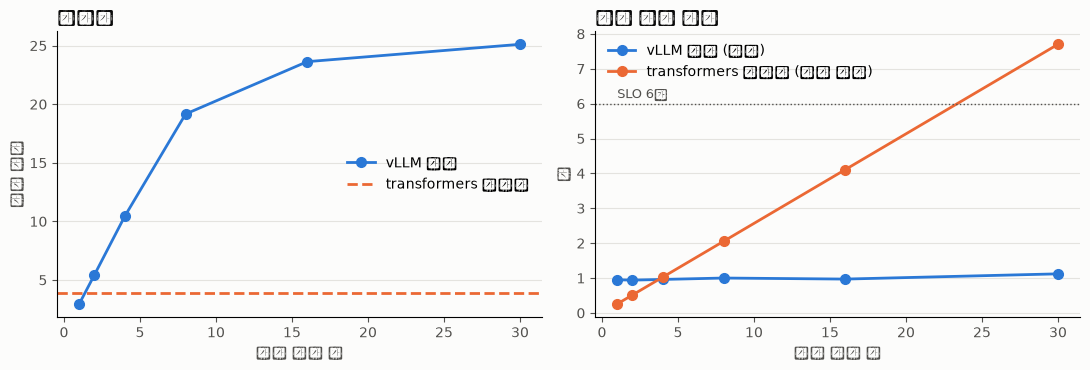

In [67]:
if LOAD:
    ns = [r["동시"] for r in LOAD]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), facecolor=SURFACE)

    ax = axes[0]
    ax.plot(ns, [r["초당 질문"] for r in LOAD], color=BLUE, linewidth=2, marker="o", markersize=7, label="vLLM 서버")
    ax.axhline(len(QUESTIONS) / hf_wall, color=ORANGE, linewidth=2, linestyle="--", label="transformers 하나씩")
    style(ax, "처리량", "초당 질문")
    ax.set_xlabel("동시 요청 수", color=INK2)
    ax.legend(frameon=False)

    ax = axes[1]
    ax.plot(ns, [r["가장 늦은 사람 초"] for r in LOAD], color=BLUE, linewidth=2, marker="o", markersize=7,
            label="vLLM 서버 (실측)")
    ax.plot(ns, [n * HF_ONE for n in ns], color=ORANGE, linewidth=2, marker="o", markersize=7,
            label="transformers 하나씩 (어림 계산)")
    ax.axhline(TARGET_SECONDS, color=INK2, linewidth=1, linestyle=":")
    ax.annotate(f"SLO {TARGET_SECONDS:.0f}초", (ns[0], TARGET_SECONDS), textcoords="offset points",
                xytext=(0, 4), color=INK2, fontsize=9)
    style(ax, "최대 지연 시간", "초")
    ax.set_xlabel("동시 요청 수", color=INK2)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

**두 그래프를 함께 읽습니다.**

- **처리량** : vLLM 선이 동시 요청 수를 따라 올라가다 어느 단계에서 꺾이는지 봅니다  
- **최대 지연 시간** : SLO 선을 처음 넘는 동시 요청 수가 응답 시간 기준 동시 요청 수의 경계입니다

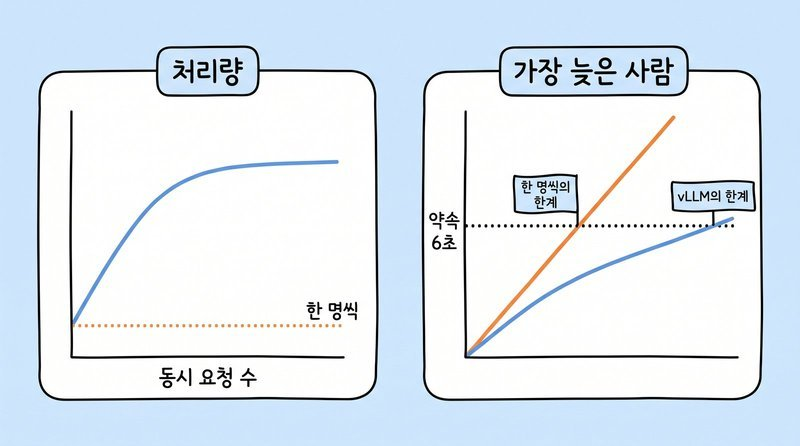

*연속 배칭은 처리량을 올리고 최대 지연 시간이 늘어나는 기울기를 낮춥니다.*

/tmp/ipykernel_2265/3006984729.py:16: UserWarning: Glyph 54168 (\N{HANGUL SYLLABLE PE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2265/3006984729.py:16: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2265/3006984729.py:16: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2265/3006984729.py:16: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2265/3006984729.py:16: UserWarning: Glyph 49885 (\N{HANGUL SYLLABLE SIG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2265/3006984729.py:16: UserWarning: Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2265/3006984729.py:16: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout

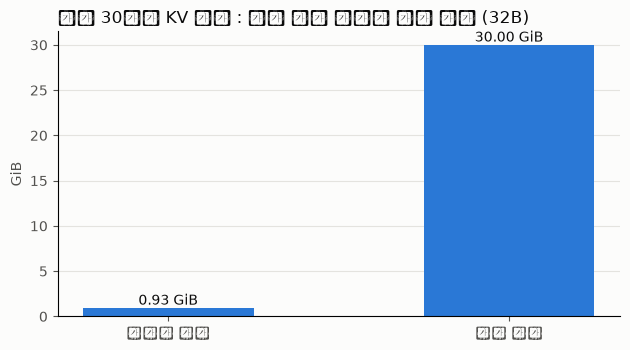

In [68]:
RESERVE = int(os.environ.get("D57_RESERVE_TOKENS", "4096"))   # 모델 선택 노트 코드가 요청마다 할당한 길이
PAGES = None
if AVG_PAGES:
    PAGES = {"페이지 방식": AVG_PAGES * len(QUESTIONS) * PAGE_BYTES / 1024 ** 3,
             "미리 잡기": pages_for(RESERVE) * len(QUESTIONS) * PAGE_BYTES / 1024 ** 3}
if PAGES is None:
    print("그릴 값이 없습니다. Step 4를 먼저 실행하세요")
else:
    fig, ax = plt.subplots(figsize=(6.4, 3.6), facecolor=SURFACE)
    names = ["페이지 방식", "미리 잡기"]
    bars = ax.bar(names, [PAGES[n] for n in names], color=BLUE, width=0.5)
    for b, n in zip(bars, names):
        ax.annotate(f"{PAGES[n]:.2f} GiB", (b.get_x() + b.get_width() / 2, b.get_height()),
                    ha="center", va="bottom", color=INK, fontsize=10)
    style(ax, "질문 30개의 KV 캐시 : 쓰는 만큼 받기와 미리 잡기 (32B)", "GiB")
    plt.tight_layout()
    plt.show()

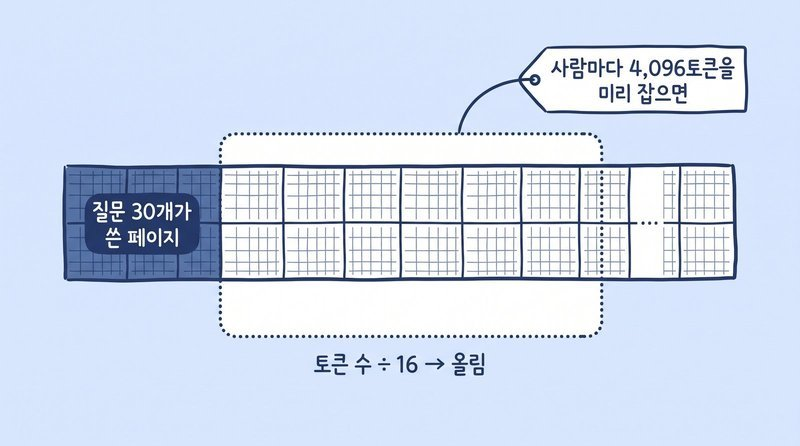

*같은 질문 30개라도 쓰는 만큼 KV 블록을 할당하면 미리 할당하는 방식보다 KV 캐시를 훨씬 적게 씁니다.*

**두 막대의 차이가 모델 선택 노트 코드가 말한 낭비입니다.** 우리 질문은 짧아서 블록 단위로 할당하면(그래프의 '페이지 방식' 막대) KV 캐시의 몇 퍼센트만 씁니다.

## 부록 실습 C. 동시에 들어가도 차례로 처리되는 transformers

이론 노트 1장 심화 ‘요청을 하나씩 처리하던 지난 서버’의 측정을 7B로 다시 합니다. 스레드 여러 개가 같은 모델의 `generate`를 동시에 호출해도 경과 시간이 줄어드는지 봅니다. vLLM 서버를 모두 종료하고 7B를 다시 로드합니다.

In [69]:
for nm in list(SERVERS):
    print(nm, stop_server(SERVERS[nm]))
h16["model"] = AutoModelForCausalLM.from_pretrained(MODEL_16, dtype=DTYPE16, device_map={"": 0}).eval()

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

In [70]:
HF_WORKERS = int(os.environ.get("D57_HF_WORKERS", "4"))


def run_hf_threads(questions, workers=HF_WORKERS):
    """에어갭 RAG 노트 트랙 1의 구성 : 스레드 여러 개가 같은 모델의 generate를 동시에 호출합니다"""
    start = time.perf_counter()

    def one(q):
        ans = ask(h16, q["q"], max_new_tokens=max_new(q))
        return {"id": q["id"], "answer": ans, "correct": check_answer(ans, q["kind"], q["answer"]),
                "tokens": n_tokens(ans), "done_at": time.perf_counter() - start}

    with ThreadPoolExecutor(max_workers=workers) as ex:
        rows = list(ex.map(one, questions))
    return rows, time.perf_counter() - start


thr_rows, thr_wall = run_hf_threads(QUESTIONS)
record(f"transformers 16비트 스레드 {HF_WORKERS}개", thr_rows, thr_wall, "transformers", workers=HF_WORKERS)
print(f"경과 시간 : 하나씩 {hf_wall:.1f}초 / 스레드 {HF_WORKERS}개 {thr_wall:.1f}초")
h16["model"] = None
gc.collect()
torch.cuda.empty_cache()

[transformers 16비트 스레드 4개] {'정답': 23, '경과 초': 11.68, '생성 토큰': 214, '초당 토큰': 18.33, '가장 늦은 사람 초': 11.67}
경과 시간 : 하나씩 7.7초 / 스레드 4개 11.7초


**두 경과 시간을 비교합니다.** 스레드를 넷으로 늘렸는데 경과 시간이 거의 그대로라면 동시에 들어가도 동시에 처리되지 않았습니다.

## 부록 실습 D. 스트리밍 백엔드와 헬스체크 판정

질문과 근거 문서를 받아 vLLM의 답을 청크로 내놓는 동기 제너레이터를 만들고 소비하는 쪽이 제너레이터를 닫으면 vLLM의 실행 큐가 비는지 확인합니다(이론 노트 5장 심화 ‘설정의 곁가지’). 이어서 vLLM의 `/health`를 게이트웨이 상태 값으로 바꾸는 판정 규칙을 표로 테스트합니다(이론 노트 4.5절). Step 6의 팀 설정 서버가 기동되어 있어야 합니다.

먼저 vLLM 서버의 키가 `/v1` 아래에만 걸리는지 확인합니다(이론 노트 4.2절). 키 없이 호출한 `/v1/models`는 401이어야 합니다.

In [71]:
# 키가 걸린 경로와 열린 경로를 직접 확인합니다(이론 노트 4.2절)
if alive(srv):
    for path, headers in [("/health", {}), ("/v1/models", {}),
                          ("/v1/models", {"Authorization": f"Bearer {VLLM_KEY}"})]:
        r = httpx.get(srv["base"] + path, headers=headers, timeout=5)
        print(f"{path:<12} 키 {'있음' if headers else '없음'} -> {r.status_code} {r.text[:60]!r}")

In [72]:
%%writefile vllm_backend.py
"""질문과 근거 문서를 받아 vLLM 의 답을 청크로 내놓는 스트리밍 생성 백엔드.

  generate_tokens(question, docs) : 동기 제너레이터. 실패는 예외 대신 안내 문장으로 내놓습니다
주소, 키, 모델 이름은 환경 변수에서 읽습니다. 코드에 적지 않습니다
"""
import json
import os

import httpx

BASE = os.environ.get("D57_VLLM_URL", "http://127.0.0.1:8570")
KEY = os.environ.get("D57_VLLM_KEY", "")
MODEL = os.environ.get("D57_SERVED_NAME", "team-llm")
SYSTEM = os.environ.get("D57_SYSTEM", "당신은 한국 회사의 사내 규정 안내 담당자입니다. "
                                      "답변은 반드시 한국어로만 작성하세요.")
MAX_NEW = int(os.environ.get("D57_MAX_NEW_TOKENS", "300"))
TIMEOUT = float(os.environ.get("D57_STREAM_TIMEOUT", "120"))
FAIL_TEXT = "답을 만드는 중에 서버에서 문제가 생겨 멈췄습니다. 잠시 뒤 다시 질문해 주십시오."
TOO_LONG_TEXT = ("질문과 근거 문서를 합친 길이가 이 서버의 상한을 넘었습니다. "
                 "질문을 나누거나 근거를 줄여 다시 질문해 주십시오.")

LAST = {}        # 마지막 요청의 기록


def _messages(question, docs):
    context = "\n\n".join(f"[{d['제목']}]\n{d['본문']}" for d in docs) or "(근거 문서 없음)"
    return [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": f"근거 문서 :\n{context}\n\n질문 : {question}"}]


def generate_tokens(question, docs):
    """소비하는 쪽이 제너레이터를 닫으면 with 블록이 연결을 끊고 vLLM이 그 요청을 취소합니다"""
    body = {"model": MODEL, "messages": _messages(question, docs), "max_tokens": MAX_NEW,
            "temperature": 0.0, "stream": True}
    headers = {"Authorization": f"Bearer {KEY}"}
    LAST.clear()
    LAST.update({"조각": 0, "오류": None})
    try:
        with httpx.stream("POST", BASE + "/v1/chat/completions", json=body,
                          headers=headers, timeout=TIMEOUT) as r:
            if r.status_code != 200:
                text = r.read().decode("utf-8", errors="replace")
                LAST["오류"] = f"HTTP {r.status_code} : {text[:120]}"
                # 길이 상한을 넘은 요청은 400번대로 반환됩니다(이론 노트 5.2절)
                yield TOO_LONG_TEXT if "maximum context length" in text else FAIL_TEXT
                return
            for line in r.iter_lines():
                if not line.startswith("data: "):
                    continue
                data = line[len("data: "):]
                if data.strip() == "[DONE]":
                    break
                delta = json.loads(data)["choices"][0].get("delta", {}).get("content")
                if delta:
                    LAST["조각"] += 1
                    yield delta
    except httpx.HTTPError as e:
        LAST["오류"] = type(e).__name__
        yield FAIL_TEXT

Writing vllm_backend.py


In [73]:
import importlib

if alive(srv):
    os.environ.update({"D57_VLLM_URL": srv["base"], "D57_VLLM_KEY": VLLM_KEY, "D57_SERVED_NAME": SERVED_NAME})
    import vllm_backend
    importlib.reload(vllm_backend)
    DOCS = [{"제목": "휴가 규정 제7조", "본문": "연차는 최대 5일까지 다음 해로 이월할 수 있고 승인권자는 인사팀장이다."},
            {"제목": "재택근무 지침", "본문": "재택근무는 주 2회 이내에서 부서장 승인을 받아 신청한다."}]
    t0 = time.perf_counter()
    it = vllm_backend.generate_tokens("연차를 다음 해로 넘길 수 있습니까? 누가 승인합니까?", DOCS)
    first = next(it)
    TTFT = time.perf_counter() - t0
    pieces = [first] + list(it)
    print(f"첫 청크 {TTFT:.2f}초, 전체 {time.perf_counter() - t0:.1f}초, 청크 {vllm_backend.LAST['조각']}개")
    print("답 :", "".join(pieces)[:200])
else:
    print("vLLM 서버가 없습니다. Step 6의 기동 셀을 다시 실행하세요")

vLLM 서버가 없습니다. Step 6의 기동 셀을 다시 실행하세요


청크 열 개만 받고 제너레이터를 닫은 뒤 `/metrics`의 실행 큐가 비는지 봅니다.

In [74]:
def running(base):
    """/metrics의 실행 큐 길이"""
    lines = httpx.get(base + "/metrics", timeout=2).text.splitlines()
    return sum(float(l.rsplit(" ", 1)[1]) for l in lines if l.startswith("vllm:num_requests_running"))


if alive(srv):
    it = vllm_backend.generate_tokens("재택근무 규정을 열 문장으로 자세히 설명해 주십시오.", DOCS)
    got = [next(it) for _ in range(10)]
    during = running(srv["base"])
    it.close()                                # 제너레이터를 닫으면 HTTP 연결이 끊깁니다
    time.sleep(1.5)
    after_close = running(srv["base"])
    print(f"받은 청크 {len(got)}개 / 닫기 전 실행 큐 {during} / 닫은 뒤 실행 큐 {after_close}")

**닫은 뒤 실행 큐가 0이어야 합니다.** 연결을 끊은 요청은 vLLM도 생성을 멈추므로 GPU 시간을 더 쓰지 않습니다.

**서버 상태 확인 규칙**

52일차 서버의 `/health`는 vLLM이 중단돼도 `healthy`를 반환합니다. vLLM의 `/health` 결과를 게이트웨이 상태 값으로 바꾸는 규칙을 만듭니다. 요청을 받을 준비가 되었는지 확인하지 못하면 정상으로 판정하지 않고, 표의 사례로 규칙을 먼저 시험합니다.

In [75]:
# 실습 : vLLM의 /health 결과를 게이트웨이 노트의 상태 값으로 바꾸는 판정 함수를 완성하세요(이론 노트 4.5절)
# status는 HTTP 상태 코드 또는 None, error는 예외 이름 문자열 또는 None입니다

def health_state(status, error):
    if error == "ConnectError":
        return "loading"                # 모델을 로드하는 중입니다. 오래 이어지면 사람이 확인합니다
    ### START CODE HERE ### (오류 없이 200 일 때만 healthy 로 판정하기 2줄)
    # 1) 오류가 없고(error is None) 상태가 200 이면 "healthy" 를 반환합니다
    if error is None and status == 200:
        return "healthy"
    ### END CODE HERE ###
    return "down"                       # 503(엔진이 비정상 종료됨)을 포함한 그 밖의 모든 경우. 모르면 불합격입니다

<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
if error is None and status == 200:
    return "healthy"
```

**200이라도 오류가 함께 있으면 down입니다.**

</details>

In [76]:
CASES = [(200, None, "healthy"), (503, None, "down"), (None, "ConnectError", "loading"),
         (None, "ReadTimeout", "down"), (500, None, "down"), (404, None, "down"), (200, "ReadTimeout", "down")]

if health_state(200, None) is None:
    print("health_state가 비어 있습니다. 실습 셀을 채우고 이 셀을 다시 실행하세요")
else:
    wrong = [(s, e, want, health_state(s, e)) for s, e, want in CASES if health_state(s, e) != want]
    print(f"판정표 {len(CASES)}건 중 어긋남 {len(wrong)}건 {wrong if wrong else ''}")
    empty = pick_port(PORT_START + 1, PORT_START + 9)              # 아무도 듣지 않는 포트
    for name, base in [("지금 vLLM 서버", srv.get("base")), ("기동되지 않은 주소", f"http://127.0.0.1:{empty}")]:
        if base is None:
            continue
        try:
            print(name, ":", health_state(httpx.get(base + "/health", timeout=2).status_code, None))
        except httpx.HTTPError as e:
            print(name, ":", health_state(None, type(e).__name__))

판정표 7건 중 어긋남 0건 
지금 vLLM 서버 : loading
기동되지 않은 주소 : loading


## 부록 실습 E. GPU 한 장에 vLLM 둘

이론 노트 5장 심화 ‘설정의 곁가지’의 두 vLLM을 실제로 기동합니다. 32B 4비트는 둘이 들어가지 않으므로 7B 16비트 서버 둘에 비율을 0.45씩 주고 차례로 기동해 각자의 KV 캐시 토큰 수를 Step 5의 D 행(7B 서버 하나)과 비교합니다.

In [77]:
# 실습 : 비율 0.45로 7B 서버 둘을 차례로 기동하고 각자의 기동 기록을 TWO에 담으세요
for nm in list(SERVERS):
    print(nm, stop_server(SERVERS[nm]))
TWO = []
for i in range(2):
    print(f"{i + 1}번째 서버 전 남은 메모리 {fmt(free_gpu_gib(), '.2f')} GiB")
    ### START CODE HERE ### (메모리 비율 0.45 로 i 번째 서버 기동하기 1줄)
    # 1) 이름 f"e_{i}", 모델 MODEL_16, 비율 0.45 로 start_server 를 호출합니다
    s_i = start_server(f"e_{i}", MODEL_16, 0.45)
    ### END CODE HERE ###
    if s_i is None:
        print("TWO가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
        break
    if "error" in s_i:
        TWO.append({"error": s_i["error"]})
        break
    TWO.append({"util": 0.45, **(startup_info(s_i) or {})})

one_kv = TEAM_ROWS.get("D 7B 16비트", {}).get("kv_tokens")
for i, t in enumerate(TWO):
    print(f"{i + 1}번째 : {t.get('error') or fmt(t.get('kv_tokens'), ',.0f')} 토큰 (D 행의 서버 하나 {fmt(one_kv, ',.0f')} 토큰)")
for nm in [k for k in list(SERVERS) if k.startswith("e_")]:
    print(nm, stop_server(SERVERS[nm]))

1번째 서버 전 남은 메모리 44.01 GiB


2번째 서버 전 남은 메모리 23.95 GiB
1번째 : 89,424 토큰 (D 행의 서버 하나 447,168 토큰)
2번째 : 89,424 토큰 (D 행의 서버 하나 447,168 토큰)
e_0 종료 : 남은 GPU 메모리 23.9 GiB
e_1 종료 : 남은 GPU 메모리 44.0 GiB


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
s_i = start_server(f"e_{i}", MODEL_16, 0.45)
```

**두 서버의 KV 토큰을 더해도 서버 하나일 때보다 적습니다.**

</details>

## 부록 실습 F. 첫 기동과 enforce_eager

32B 서버를 `--enforce-eager`로 기동해 준비까지의 시간과 요청 하나일 때의 초당 토큰을 Step 5의 A 기준 행과 비교합니다(이론 노트 4장 심화 ‘첫 기동을 줄이는 설정과 4비트 커널’).

In [78]:
# 실습 : --enforce-eager로 서버를 기동하고 준비 시간, init 시간, 요청 하나일 때의 초당 토큰을 기준 서버와 비교하세요
EAGER = None
for nm in list(SERVERS):
    print(nm, stop_server(SERVERS[nm]))

### START CODE HERE ### (--enforce-eager 를 붙여 서버 기동하기 1줄)
# 1) start_server 에 이름 "f_eager", 모델 MODEL_ID, 비율 decide_util()[0], extra=("--enforce-eager",) 를 넘깁니다
s4 = start_server("f_eager", MODEL_ID, decide_util()[0], extra=("--enforce-eager",))
### END CODE HERE ###
if s4 is None:
    print("EAGER가 비어 있습니다. 실습 셀을 채우고 다시 실행하세요")
elif "error" in s4:
    print("기동 실패 :", s4["error"])
else:
    info4 = startup_info(s4) or {}
    EAGER = {"준비 초": s4["start_sec"], "init 초": info4.get("init_sec"), "KV 토큰": info4.get("kv_tokens"),
             **{k: v for k, v in measure(s4).items() if k in ("혼자 초당 토큰", "최대 지연 초")}}
    print(stop_server(s4))
    base_row = TEAM_ROWS.get("A 기준", {})
    print("enforce_eager :", EAGER)
    print("기준         :", {"준비 초": base_row.get("start_sec"), "init 초": base_row.get("init_sec"),
                              "KV 토큰": base_row.get("kv_tokens"), "혼자 초당 토큰": base_row.get("혼자 초당 토큰"),
                              "최대 지연 초": base_row.get("최대 지연 초")})

종료 : 남은 GPU 메모리 44.0 GiB
enforce_eager : {'준비 초': 100.4, 'init 초': 5.38, 'KV 토큰': 90368.0, '혼자 초당 토큰': 14.2, '최대 지연 초': 1.38}
기준         : {'준비 초': 115.6, 'init 초': 75.61, 'KV 토큰': 82704.0, '혼자 초당 토큰': 15.4, '최대 지연 초': 1.31}


<details class="lms-answer">
<summary>풀이 보기</summary>

**빈칸 정답 코드 (`### START CODE HERE ###` 영역)**

```python
s4 = start_server("f_eager", MODEL_ID, decide_util()[0], extra=("--enforce-eager",))
```

**기동이 빨라지고 KV 토큰이 조금 늘어나는 대신 요청 하나일 때의 속도가 줄어드는지** 봅니다.

</details>

## 부록 실습 G. 다른 팀의 결과 파일과 나란히

다른 팀의 `d57_results.json`을 받아 같은 이름의 행을 나란히 놓습니다. 두 팀의 GPU가 다르면 백엔드와 경과 시간이 함께 바뀝니다.

In [79]:
OTHER = Path(os.environ.get("D57_OTHER_RESULTS", "/workspace/results/d57_other_team.json"))

if not OTHER.exists():
    print(f"{OTHER}가 없습니다. 다른 팀의 d57_results.json을 이 이름으로 올리고 다시 실행하세요")
else:
    other = json.loads(OTHER.read_text(encoding="utf-8"))
    print("GPU :", results["_conditions"]["gpu"], "/", other.get("_conditions", {}).get("gpu"))
    print(f"{'행':<30} {'우리 경과':>10} {'다른 팀 경과':>12} {'우리 백엔드':>14} {'다른 팀 백엔드':>15}")
    for name in results:
        a, b = results[name], other.get(name)
        if not isinstance(b, dict) or "경과 초" not in a or "경과 초" not in b:
            continue
        ba = (a.get("startup") or {}).get("backend") or "-"
        bb = (b.get("startup") or {}).get("backend") or "-"
        print(f"{name:<30} {a['경과 초']:>10} {b['경과 초']:>12} {ba:>14} {bb:>15}")

/workspace/results/d57_other_team.json가 없습니다. 다른 팀의 d57_results.json을 이 이름으로 올리고 다시 실행하세요


**답을 생성하는 도구를 바꾸기 전과 후의 행에서 요청 처리 시간을 비교합니다. GPU도 달라졌다면 시간 차이가 도구 변경의 효과인지만 따로 판단할 수 없습니다.** GPU가 바뀌면 메모리 대역폭과 계산 장치가 함께 바뀌므로 백엔드 하나의 영향만 분리해 말하기는 어렵습니다.